In [1]:

from pathlib import Path
from importlib.util import find_spec
import hashlib
import pandas as pd
import sys

input_root = Path("/kaggle/input")

assert input_root.is_dir()

print("ATTACHED KAGGLE DATASETS")

for folder in sorted(
    (input_root / "datasets").glob("*/*")
):
    if folder.is_dir():
        print(folder)

manifest_files = sorted(
    input_root.rglob("D2_split_manifest.csv")
)

print("\nD2 MANIFEST CANDIDATES")

for path in manifest_files:
    print(path)

assert len(manifest_files) == 1, (
    "Expected exactly one D2 split manifest."
)

d2_manifest_path = manifest_files[0]

d2_manifest = pd.read_csv(
    d2_manifest_path
)

required_columns = {
    "rel_path",
    "class_id",
    "split"
}

assert required_columns.issubset(
    d2_manifest.columns
)

expected_counts = {
    "train": 3327,
    "val": 712,
    "test": 713
}

actual_counts = (
    d2_manifest["split"].value_counts().to_dict()
)

assert len(d2_manifest) == 4752
assert actual_counts == expected_counts
assert d2_manifest["rel_path"].is_unique
assert d2_manifest["rel_path"].notna().all()
assert set(d2_manifest["class_id"]) == set(range(4))

manifest_hash = hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest()

print("\nD2 DATASET VERIFICATION")
print("Retained images:", len(d2_manifest))
print("Training images:", actual_counts["train"])
print("Validation images:", actual_counts["val"])
print("Test images:", actual_counts["test"])
print("Classes:", d2_manifest["class_id"].nunique())
print("Manifest SHA256:", manifest_hash)

print("\nSAMPLE IMAGE PATHS")

for path in d2_manifest["rel_path"].head(3):
    print(path)

print("\nSOFTWARE ENVIRONMENT")
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print(
    "TensorFlow installed:",
    find_spec("tensorflow") is not None
)

print("\nPAPER 1 D2 INITIAL VERIFICATION: PASSED")


ATTACHED KAGGLE DATASETS
/kaggle/input/datasets/nayebul0/assignment02-d2-rice-leaf-5932
/kaggle/input/datasets/nayebul0/assignment02-verified-train-val-test-splits

D2 MANIFEST CANDIDATES
/kaggle/input/datasets/nayebul0/assignment02-verified-train-val-test-splits/D2_split_manifest.csv

D2 DATASET VERIFICATION
Retained images: 4752
Training images: 3327
Validation images: 712
Test images: 713
Classes: 4
Manifest SHA256: 261b97b6fa700197f2dde6bc0f833bf802bd1301c0611606400e990cfad2a185

SAMPLE IMAGE PATHS
Bacterialblight/BACTERAILBLIGHT3_007.jpg
Bacterialblight/BACTERAILBLIGHT3_011.jpg
Bacterialblight/BACTERAILBLIGHT3_022.jpg

SOFTWARE ENVIRONMENT
Python: 3.13.16
Pandas: 2.3.3
TensorFlow installed: True

PAPER 1 D2 INITIAL VERIFICATION: PASSED


In [2]:

from pathlib import Path
from PIL import Image
import hashlib
import pandas as pd
import tensorflow as tf
import keras

# Verify the frozen D2 manifest.
expected_d2_hash = (
    "261b97b6fa700197f2dde6bc0f833bf"
    "802bd1301c0611606400e990cfad2a185"
)

actual_d2_hash = hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest()

assert actual_d2_hash == expected_d2_hash

# Locate the actual image root automatically.
sample_rel = Path(
    str(d2_manifest.iloc[0]["rel_path"])
)

matches = sorted(
    Path("/kaggle/input").rglob(sample_rel.name)
)

candidate_roots = []

for match in matches:
    root = match

    for _ in sample_rel.parts:
        root = root.parent

    if (root / sample_rel) == match:
        candidate_roots.append(root)

candidate_roots = sorted(set(candidate_roots))

print("D2 IMAGE ROOT CANDIDATES")

for root in candidate_roots:
    print(root)

complete_roots = []

for root in candidate_roots:
    present = sum(
        (root / str(rel_path)).is_file()
        for rel_path in d2_manifest["rel_path"]
    )

    print("Root:", root)
    print("Matching images:", present)

    if present == len(d2_manifest):
        complete_roots.append(root)

assert len(complete_roots) == 1, (
    "Expected exactly one complete D2 image root."
)

D2_ROOT = complete_roots[0]

# Confirm that every retained image exists.
missing = [
    str(rel_path)
    for rel_path in d2_manifest["rel_path"]
    if not (D2_ROOT / str(rel_path)).is_file()
]

assert not missing

# Decode a representative image from each class.
class_names = {}

for class_id in range(4):
    rows = d2_manifest[
        d2_manifest["class_id"] == class_id
    ]

    names = {
        Path(str(path)).parts[0]
        for path in rows["rel_path"]
    }

    assert len(names) == 1

    class_names[class_id] = next(iter(names))

    image_path = (
        D2_ROOT /
        str(rows.iloc[0]["rel_path"])
    )

    with Image.open(image_path) as image:
        image = image.convert("RGB")
        image.load()

        assert image.width > 0
        assert image.height > 0

        print(
            f"Class {class_id}: "
            f"{class_names[class_id]} — "
            f"sample decoded: {image.size}"
        )

assert len(set(class_names.values())) == 4

print("\nD2 IMAGE VERIFICATION")
print("D2 image root:", D2_ROOT)
print("Images found:", len(d2_manifest))
print("Missing images:", len(missing))
print("Sample images decoded:", 4)
print("Classes:", len(class_names))

print("\nTENSORFLOW ENVIRONMENT")
print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)
print(
    "Available GPUs:",
    tf.config.list_physical_devices("GPU")
)

print("\nMANIFEST INTEGRITY")
print("SHA256:", actual_d2_hash)
print("Manifest unchanged: True")

print("\nPAPER 1 D2 IMAGE AND ENVIRONMENT: PASSED")


D2 IMAGE ROOT CANDIDATES
/kaggle/input/datasets/nayebul0/assignment02-d2-rice-leaf-5932/Rice Leaf Disease Images
Root: /kaggle/input/datasets/nayebul0/assignment02-d2-rice-leaf-5932/Rice Leaf Disease Images
Matching images: 4752
Class 0: Bacterialblight — sample decoded: (300, 300)
Class 1: Blast — sample decoded: (300, 300)
Class 2: Brownspot — sample decoded: (300, 300)
Class 3: Tungro — sample decoded: (210, 280)

D2 IMAGE VERIFICATION
D2 image root: /kaggle/input/datasets/nayebul0/assignment02-d2-rice-leaf-5932/Rice Leaf Disease Images
Images found: 4752
Missing images: 0
Sample images decoded: 4
Classes: 4

TENSORFLOW ENVIRONMENT
TensorFlow version: 2.21.0
Keras version: 3.13.2
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

MANIFEST INTEGRITY
SHA256: 261b97b6fa700197f2dde6bc0f833bf802bd1301c0611606400e990cfad2a185
Manifest unchanged: True

PAPER 1 D2 IMAGE AND ENVIRONMENT: PASSED

In [3]:

import hashlib
import numpy as np
import tensorflow as tf
import keras

from keras import layers

SEED = 2026
NUM_CLASSES = 4
INPUT_SIZE = (224, 224)

# Verify that the D2 manifest has not changed.
expected_d2_hash = (
    "261b97b6fa700197f2dde6bc0f833bf"
    "802bd1301c0611606400e990cfad2a185"
)

actual_d2_hash = hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest()

assert actual_d2_hash == expected_d2_hash

# Start a fresh D2 model.
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

# Load original ImageNet pretrained weights.
# Do not load any D1 checkpoint.
backbone = keras.applications.MobileNetV3Large(
    input_shape=(224, 224, 3),
    alpha=1.0,
    minimalistic=False,
    include_top=False,
    weights="imagenet",
    include_preprocessing=True
)

# Paper 1 Stage 1: freeze the backbone.
backbone.trainable = False

# Build the paper's classification head.
inputs = keras.Input(
    shape=(224, 224, 3),
    name="rice_leaf_input"
)

features = backbone(
    inputs,
    training=False
)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(features)

x = layers.Dense(
    128,
    activation="relu",
    name="custom_dense_128"
)(x)

x = layers.Dropout(
    0.5,
    name="custom_dropout"
)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="rice_disease_predictions"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="Paper1_MobileNetV3Large_D2"
)

# Calculate actual model parameters.
total_params = model.count_params()

trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in model.trainable_weights
)

frozen_params = sum(
    int(np.prod(weight.shape))
    for weight in model.non_trainable_weights
)

# Verify architecture.
assert len(backbone.layers) == 187

assert backbone.output_shape == (
    None, 7, 7, 960
)

assert model.input_shape == (
    None, 224, 224, 3
)

assert model.output_shape == (
    None, 4
)

assert backbone.trainable is False

assert all(
    not layer.trainable
    for layer in backbone.layers
)

assert model.get_layer(
    "custom_dense_128"
).units == 128

assert model.get_layer(
    "custom_dropout"
).rate == 0.5

assert model.get_layer(
    "rice_disease_predictions"
).units == 4

assert total_params == 3119876
assert trainable_params == 123524
assert frozen_params == 2996352

assert total_params == (
    trainable_params + frozen_params
)

# Perform one synthetic forward pass.
sample_input = tf.zeros(
    (1, 224, 224, 3),
    dtype=tf.float32
)

sample_output = model(
    sample_input,
    training=False
)

assert tuple(sample_output.shape) == (1, 4)

assert bool(
    tf.reduce_all(
        tf.math.is_finite(sample_output)
    )
)

assert np.allclose(
    tf.reduce_sum(
        sample_output,
        axis=1
    ).numpy(),
    1.0,
    atol=1e-5
)

print("D2 MODEL ARCHITECTURE")
print("Model:", model.name)
print("Backbone:", backbone.name)
print("Backbone layers:", len(backbone.layers))
print("Backbone output:", backbone.output_shape)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

print("\nMODEL PARAMETERS")
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", frozen_params)

print("\nARCHITECTURE VERIFICATION")
print("ImageNet weights: LOADED")
print("D1 weights used: NO")
print("Backbone frozen:", not backbone.trainable)
print("Custom dense units: 128")
print("Dropout rate: 0.5")
print("Output classes:", NUM_CLASSES)
print("Forward pass: PASSED")
print("Softmax probability sum: PASSED")

print("\nTRAINING STATUS")
print("Stage 1 started: NO")
print("Stage 2 started: NO")

print("\nPAPER 1 D2 ARCHITECTURE: PASSED")


12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
D2 MODEL ARCHITECTURE
Model: Paper1_MobileNetV3Large_D2
Backbone: MobileNetV3Large
Backbone layers: 187
Backbone output: (None, 7, 7, 960)
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)

MODEL PARAMETERS
Total parameters: 3119876
Trainable parameters: 123524
Frozen parameters: 2996352

ARCHITECTURE VERIFICATION
ImageNet weights: LOADED
D1 weights used: NO
Backbone frozen: True
Custom dense units: 128
Dropout rate: 0.5
Output classes: 4
Forward pass: PASSED
Softmax probability sum: PASSED

TRAINING STATUS
Stage 1 started: NO
Stage 2 started: NO

PAPER 1 D2 ARCHITECTURE: PASSED


In [4]:

import hashlib
import numpy as np
import tensorflow as tf
import keras

SEED = 2026

# Verify the frozen D2 manifest.
expected_d2_hash = (
    "261b97b6fa700197f2dde6bc0f833bf"
    "802bd1301c0611606400e990cfad2a185"
)

assert hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest() == expected_d2_hash

keras.utils.set_random_seed(SEED)

# Same augmentation configuration used for D1.
paper1_augmentation = keras.Sequential(
    [
        keras.layers.RandomRotation(
            0.05,
            fill_mode="reflect",
            seed=SEED + 1
        ),
        keras.layers.RandomFlip(
            "horizontal",
            seed=SEED + 2
        ),
        keras.layers.RandomZoom(
            0.1,
            fill_mode="reflect",
            seed=SEED + 3
        ),
        keras.layers.RandomBrightness(
            factor=0.1,
            value_range=(0.0, 1.0),
            seed=SEED + 4
        ),
        keras.layers.GaussianNoise(
            stddev=0.1,
            seed=SEED + 5
        )
    ],
    name="paper1_training_augmentation"
)


def paper1_load_image(rel_path):
    path = D2_ROOT / str(rel_path)

    image_bytes = tf.io.read_file(str(path))

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        tf.cast(image, tf.float32),
        [224, 224],
        method="bilinear"
    )

    return tf.clip_by_value(
        image,
        0.0,
        255.0
    )


def paper1_transform(image, training=False):
    image = tf.cast(image, tf.float32)

    if training:
        normalized = image / 255.0

        normalized = paper1_augmentation(
            tf.expand_dims(normalized, axis=0),
            training=True
        )[0]

        image = tf.clip_by_value(
            normalized,
            0.0,
            1.0
        ) * 255.0

    return image


# Select images only from training and validation.
train_row = d2_manifest[
    d2_manifest["split"] == "train"
].iloc[0]

val_row = d2_manifest[
    d2_manifest["split"] == "val"
].iloc[0]

train_original = paper1_load_image(
    train_row["rel_path"]
)

train_augmented = paper1_transform(
    train_original,
    training=True
)

val_original = paper1_load_image(
    val_row["rel_path"]
)

val_first = paper1_transform(
    val_original,
    training=False
)

val_second = paper1_transform(
    val_original,
    training=False
)

# Verify image shapes and types.
assert tuple(train_original.shape) == (
    224, 224, 3
)

assert tuple(train_augmented.shape) == (
    224, 224, 3
)

assert tuple(val_first.shape) == (
    224, 224, 3
)

assert train_augmented.dtype == tf.float32
assert val_first.dtype == tf.float32

# Verify numerical safety and pixel ranges.
for image in [train_augmented, val_first]:
    assert bool(
        tf.reduce_all(tf.math.is_finite(image))
    )

    assert float(
        tf.reduce_min(image).numpy()
    ) >= 0.0

    assert float(
        tf.reduce_max(image).numpy()
    ) <= 255.0

# Validation must be deterministic.
validation_deterministic = np.array_equal(
    val_first.numpy(),
    val_second.numpy()
)

# Training should apply a random transformation.
training_image_changed = not np.array_equal(
    train_original.numpy(),
    train_augmented.numpy()
)

assert validation_deterministic
assert training_image_changed

# Verify compatibility with the four-class model.
real_image_output = model(
    tf.expand_dims(val_first, axis=0),
    training=False
)

assert tuple(real_image_output.shape) == (
    1, 4
)

assert bool(
    tf.reduce_all(
        tf.math.is_finite(real_image_output)
    )
)

assert np.allclose(
    np.sum(real_image_output.numpy(), axis=1),
    1.0,
    atol=1e-5
)

print("D2 PREPROCESSING VERIFICATION")
print("Dataset: D2")
print("Input size:", tuple(train_original.shape))
print("Training augmentation:", training_image_changed)
print("Validation deterministic:", validation_deterministic)

print("\nPIXEL VERIFICATION")
print("Training dtype:", train_augmented.dtype)
print(
    "Training pixel range:",
    round(float(tf.reduce_min(train_augmented)), 3),
    round(float(tf.reduce_max(train_augmented)), 3)
)
print(
    "Validation pixel range:",
    round(float(tf.reduce_min(val_first)), 3),
    round(float(tf.reduce_max(val_first)), 3)
)

print("\nMODEL COMPATIBILITY")
print("Model:", model.name)
print("Expected input range: 0–255")
print("Output classes:", real_image_output.shape[-1])
print("Real-image forward pass: PASSED")
print("Softmax probability sum: PASSED")

print("\nTRAINING STATUS")
print("Stage 1 started: NO")
print("Stage 2 started: NO")
print("Test images accessed: NO")

print("\nPAPER 1 D2 PREPROCESSING: PASSED")


D2 PREPROCESSING VERIFICATION
Dataset: D2
Input size: (224, 224, 3)
Training augmentation: True
Validation deterministic: True

PIXEL VERIFICATION
Training dtype: <dtype: 'float32'>
Training pixel range: 0.0 255.0
Validation pixel range: 0.0 247.303

MODEL COMPATIBILITY
Model: Paper1_MobileNetV3Large_D2
Expected input range: 0–255
Output classes: 4
Real-image forward pass: PASSED
Softmax probability sum: PASSED

TRAINING STATUS
Stage 1 started: NO
Stage 2 started: NO
Test images accessed: NO

PAPER 1 D2 PREPROCESSING: PASSED


In [5]:

import hashlib
import numpy as np
import tensorflow as tf

SEED = 2026
BATCH_SIZE = 32

expected_d2_hash = (
    "261b97b6fa700197f2dde6bc0f833bf"
    "802bd1301c0611606400e990cfad2a185"
)

actual_d2_hash = hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest()

assert actual_d2_hash == expected_d2_hash

# Use only the frozen training and validation partitions.
d2_train_rows = (
    d2_manifest[d2_manifest["split"] == "train"]
    .sort_values("rel_path")
    .reset_index(drop=True)
)

d2_val_rows = (
    d2_manifest[d2_manifest["split"] == "val"]
    .sort_values("rel_path")
    .reset_index(drop=True)
)

assert len(d2_train_rows) == 3327
assert len(d2_val_rows) == 712

assert set(d2_train_rows["class_id"]) == set(range(4))
assert set(d2_val_rows["class_id"]) == set(range(4))

# Check separation of manifest paths.
train_paths = set(d2_train_rows["rel_path"])
val_paths = set(d2_val_rows["rel_path"])

test_paths = set(
    d2_manifest.loc[
        d2_manifest["split"] == "test",
        "rel_path"
    ]
)

assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)


def paper1_decode_sample(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image = tf.ensure_shape(
        image,
        [None, None, 3]
    )

    image = tf.image.resize(
        tf.cast(image, tf.float32),
        [224, 224],
        method="bilinear"
    )

    image = tf.clip_by_value(
        image,
        0.0,
        255.0
    )

    return image, label


def paper1_augment_batch(images, labels):
    normalized = images / 255.0

    normalized = paper1_augmentation(
        normalized,
        training=True
    )

    images = tf.clip_by_value(
        normalized,
        0.0,
        1.0
    ) * 255.0

    return images, labels


def build_paper1_dataset(rows, training):
    paths = [
        str(D2_ROOT / str(rel_path))
        for rel_path in rows["rel_path"]
    ]

    labels = rows["class_id"].to_numpy(
        dtype=np.int32
    )

    assert all(
        (D2_ROOT / str(rel_path)).is_file()
        for rel_path in rows["rel_path"]
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(rows),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        paper1_decode_sample,
        num_parallel_calls=1
    )

    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False
    )

    if training:
        dataset = dataset.map(
            paper1_augment_batch,
            num_parallel_calls=1
        )

    options = tf.data.Options()
    options.experimental_deterministic = True

    dataset = dataset.with_options(options)
    dataset = dataset.prefetch(1)

    return dataset


d2_train_loader = build_paper1_dataset(
    d2_train_rows,
    training=True
)

d2_val_loader = build_paper1_dataset(
    d2_val_rows,
    training=False
)

training_batches = int(
    tf.data.experimental.cardinality(
        d2_train_loader
    ).numpy()
)

validation_batches = int(
    tf.data.experimental.cardinality(
        d2_val_loader
    ).numpy()
)

assert training_batches == 104
assert validation_batches == 23

train_images, train_labels = next(
    iter(d2_train_loader)
)

val_images, val_labels = next(
    iter(d2_val_loader)
)

assert tuple(train_images.shape) == (
    32, 224, 224, 3
)

assert tuple(val_images.shape) == (
    32, 224, 224, 3
)

assert train_images.dtype == tf.float32
assert val_images.dtype == tf.float32

assert train_labels.dtype == tf.int32
assert val_labels.dtype == tf.int32

for images in [train_images, val_images]:
    assert bool(
        tf.reduce_all(tf.math.is_finite(images))
    )

    assert bool(
        tf.reduce_all(
            (images >= 0.0) &
            (images <= 255.0)
        )
    )

# Validation must produce the same batch on repeated reads.
val_images_again, val_labels_again = next(
    iter(d2_val_loader)
)

assert np.array_equal(
    val_images.numpy(),
    val_images_again.numpy()
)

assert np.array_equal(
    val_labels.numpy(),
    val_labels_again.numpy()
)

print("D2 DATA PIPELINE VERIFICATION")
print("Training images:", len(d2_train_rows))
print("Validation images:", len(d2_val_rows))
print("Test images reserved:", len(test_paths))

print("\nBATCH VERIFICATION")
print("Training batches:", training_batches)
print("Validation batches:", validation_batches)
print("Training batch shape:", tuple(train_images.shape))
print("Validation batch shape:", tuple(val_images.shape))

print("\nDATA INTEGRITY")
print("Train/validation/test paths disjoint: True")
print("Training shuffle: ENABLED")
print("Training augmentation: ENABLED")
print("Validation augmentation: DISABLED")
print("Validation deterministic: True")

print(
    "Training class IDs:",
    sorted(d2_train_rows["class_id"].unique().tolist())
)

print(
    "Validation class IDs:",
    sorted(d2_val_rows["class_id"].unique().tolist())
)

print("\nTRAINING STATUS")
print("Stage 1 started: NO")
print("Stage 2 started: NO")
print("Test images loaded: NO")

print("\nPAPER 1 D2 DATA PIPELINE: PASSED")


D2 DATA PIPELINE VERIFICATION
Training images: 3327
Validation images: 712
Test images reserved: 713

BATCH VERIFICATION
Training batches: 104
Validation batches: 23
Training batch shape: (32, 224, 224, 3)
Validation batch shape: (32, 224, 224, 3)

DATA INTEGRITY
Train/validation/test paths disjoint: True
Training shuffle: ENABLED
Training augmentation: ENABLED
Validation augmentation: DISABLED
Validation deterministic: True
Training class IDs: [0, 1, 2, 3]
Validation class IDs: [0, 1, 2, 3]

TRAINING STATUS
Stage 1 started: NO
Stage 2 started: NO
Test images loaded: NO

PAPER 1 D2 DATA PIPELINE: PASSED


In [6]:

from pathlib import Path
import hashlib
import json
import numpy as np
import tensorflow as tf
import keras

SEED = 2026
STAGE1_MAX_EPOCHS = 30
STAGE1_LR = 0.0001

# Verify the frozen D2 manifest.
EXPECTED_D2_HASH = (
    "261b97b6fa700197f2dde6bc0f833bf"
    "802bd1301c0611606400e990cfad2a185"
)

actual_d2_hash = hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest()

assert actual_d2_hash == EXPECTED_D2_HASH

# Verify dataset and model configuration.
assert len(d2_train_rows) == 3327
assert len(d2_val_rows) == 712
assert BATCH_SIZE == 32

assert model.name == "Paper1_MobileNetV3Large_D2"
assert model.output_shape == (None, 4)

assert backbone.trainable is False
assert all(
    not layer.trainable
    for layer in backbone.layers
)

trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in model.trainable_weights
)

frozen_params = sum(
    int(np.prod(weight.shape))
    for weight in model.non_trainable_weights
)

assert trainable_params == 123524
assert frozen_params == 2996352
assert model.count_params() == 3119876

# Create a separate experiment directory.
RUN_DIR = Path(
    "/kaggle/working/Assignment02_Experiment3_D2"
)

RUN_DIR.mkdir(
    parents=True,
    exist_ok=True
)

STAGE1_BEST_PATH = (
    RUN_DIR / "stage1_best.keras"
)

STAGE1_HISTORY_PATH = (
    RUN_DIR / "stage1_history.csv"
)

config_path = (
    RUN_DIR / "stage1_config.json"
)

# Protect any existing evidence.
assert not STAGE1_BEST_PATH.exists()
assert not STAGE1_HISTORY_PATH.exists()
assert not config_path.exists()

# Configure the paper's Stage 1 optimizer and loss.
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=STAGE1_LR
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ],
    jit_compile=False
)

# Configure the same callbacks used for D1.
stage1_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(STAGE1_BEST_PATH),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        restore_best_weights=False,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        verbose=1
    ),
    keras.callbacks.CSVLogger(
        filename=str(STAGE1_HISTORY_PATH)
    ),
    keras.callbacks.TerminateOnNaN()
]

# Verify training configuration.
assert isinstance(
    model.optimizer,
    keras.optimizers.Adam
)

assert np.isclose(
    float(model.optimizer.learning_rate.numpy()),
    STAGE1_LR
)

assert int(model.optimizer.iterations.numpy()) == 0

assert stage1_callbacks[0].monitor == "val_accuracy"
assert stage1_callbacks[1].monitor == "val_loss"
assert stage1_callbacks[1].patience == 5
assert stage1_callbacks[2].factor == 0.5
assert stage1_callbacks[2].patience == 3

stage1_config = {
    "experiment": "Assignment02_Experiment3_D2",
    "paper": "Paper 1",
    "model": "MobileNetV3-Large",
    "dataset": "D2",
    "manifest_sha256": actual_d2_hash,
    "seed": SEED,
    "num_classes": 4,
    "training_images": 3327,
    "validation_images": 712,
    "reserved_test_images": 713,
    "input_size": [224, 224, 3],
    "batch_size": BATCH_SIZE,
    "training_batches": 104,
    "validation_batches": 23,
    "stage": "frozen_backbone",
    "max_epochs": STAGE1_MAX_EPOCHS,
    "optimizer": "Adam",
    "initial_learning_rate": STAGE1_LR,
    "loss": "SparseCategoricalCrossentropy",
    "checkpoint_monitor": "val_accuracy",
    "early_stopping_monitor": "val_loss",
    "early_stopping_patience": 5,
    "reduce_lr_factor": 0.5,
    "reduce_lr_patience": 3,
    "pretrained_weights": "imagenet",
    "built_in_preprocessing": True,
    "train_augmentation_enabled": True,
    "validation_augmentation_enabled": False,
    "trainable_parameters": trainable_params,
    "frozen_parameters": frozen_params,
    "tensorflow_version": tf.__version__,
    "keras_version": keras.__version__
}

with config_path.open("w") as file:
    json.dump(
        stage1_config,
        file,
        indent=2
    )

assert config_path.is_file()

print("D2 STAGE 1 CONFIGURATION")
print("Model:", model.name)
print("Backbone frozen:", not backbone.trainable)
print("Optimizer:", type(model.optimizer).__name__)
print("Learning rate:", STAGE1_LR)
print("Maximum epochs:", STAGE1_MAX_EPOCHS)
print("Batch size:", BATCH_SIZE)

print("\nMODEL PARAMETERS")
print("Trainable:", trainable_params)
print("Frozen:", frozen_params)

print("\nDATASET")
print("Training images:", len(d2_train_rows))
print("Validation images:", len(d2_val_rows))
print("Test images reserved: 713")
print("Manifest SHA256:", actual_d2_hash)

print("\nCALLBACKS")
print("Checkpoint monitor:", stage1_callbacks[0].monitor)
print("Early stopping monitor:", stage1_callbacks[1].monitor)
print("Early stopping patience:", stage1_callbacks[1].patience)
print("LR reduction factor:", stage1_callbacks[2].factor)
print("LR reduction patience:", stage1_callbacks[2].patience)

print("\nEVIDENCE")
print("Configuration:", config_path)
print("Stage 1 training started: NO")
print("Test images loaded: NO")

print("\nPAPER 1 D2 STAGE 1 CONFIGURATION: PASSED")


D2 STAGE 1 CONFIGURATION
Model: Paper1_MobileNetV3Large_D2
Backbone frozen: True
Optimizer: Adam
Learning rate: 0.0001
Maximum epochs: 30
Batch size: 32

MODEL PARAMETERS
Trainable: 123524
Frozen: 2996352

DATASET
Training images: 3327
Validation images: 712
Test images reserved: 713
Manifest SHA256: 261b97b6fa700197f2dde6bc0f833bf802bd1301c0611606400e990cfad2a185

CALLBACKS
Checkpoint monitor: val_accuracy
Early stopping monitor: val_loss
Early stopping patience: 5
LR reduction factor: 0.5
LR reduction patience: 3

EVIDENCE
Configuration: /kaggle/working/Assignment02_Experiment3_D2/stage1_config.json
Stage 1 training started: NO
Test images loaded: NO

PAPER 1 D2 STAGE 1 CONFIGURATION: PASSED


In [7]:

from pathlib import Path
import hashlib
import numpy as np
import tensorflow as tf
import keras

# Check that GPU is actually available.
gpus = tf.config.list_physical_devices("GPU")

assert len(gpus) >= 1, (
    "No GPU detected. Check Kaggle accelerator settings."
)

# Verify the frozen dataset manifest.
expected_d2_hash = (
    "261b97b6fa700197f2dde6bc0f833bf"
    "802bd1301c0611606400e990cfad2a185"
)

assert hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest() == expected_d2_hash

# Check recreated dataset variables.
assert len(d2_train_rows) == 3327
assert len(d2_val_rows) == 712
assert BATCH_SIZE == 32

assert int(
    tf.data.experimental.cardinality(
        d2_train_loader
    ).numpy()
) == 104

assert int(
    tf.data.experimental.cardinality(
        d2_val_loader
    ).numpy()
) == 23

# Verify the reconstructed D2 model.
assert model.name == "Paper1_MobileNetV3Large_D2"
assert model.input_shape == (None, 224, 224, 3)
assert model.output_shape == (None, 4)
assert backbone.trainable is False

assert model.count_params() == 3119876

trainable_params = sum(
    int(np.prod(w.shape))
    for w in model.trainable_weights
)

assert trainable_params == 123524

# Verify actual GPU execution using a small operation.
with tf.device("/GPU:0"):
    a = tf.ones((256, 256), dtype=tf.float32)
    b = tf.matmul(a, a)

assert bool(
    tf.reduce_all(tf.math.is_finite(b))
)

assert "GPU" in b.device.upper(), (
    "Operation was not placed on GPU."
)

# Check whether configuration survived the restart.
RUN_DIR = Path(
    "/kaggle/working/Assignment02_Experiment3_D2"
)

config_path = RUN_DIR / "stage1_config.json"

checkpoint_path = RUN_DIR / "stage1_best.keras"
history_path = RUN_DIR / "stage1_history.csv"

assert not checkpoint_path.exists(), (
    "Existing Stage 1 checkpoint detected. "
    "Do not restart training without investigating."
)

assert not history_path.exists(), (
    "Existing Stage 1 history detected. "
    "Do not overwrite previous training evidence."
)

print("D2 GPU ENVIRONMENT VERIFICATION")
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("Visible GPUs:", len(gpus))

for gpu in gpus:
    print("GPU:", gpu.name)

print("GPU operation device:", b.device)
print("GPU execution: PASSED")

print("\nEXPERIMENT INTEGRITY")
print("D2 manifest: VERIFIED")
print("Training images:", len(d2_train_rows))
print("Validation images:", len(d2_val_rows))
print("Training batches: 104")
print("Validation batches: 23")
print("Model:", model.name)
print("Backbone frozen: True")
print("Trainable parameters:", trainable_params)

print("\nEVIDENCE")
print("Stage 1 config exists:", config_path.is_file())
print("Previous training checkpoint: NONE")
print("Previous training history: NONE")

print("\nTRAINING STATUS")
print("Stage 1 started: NO")
print("Test images accessed by this step: NO")

print("\nPAPER 1 D2 GPU ENVIRONMENT: PASSED")


D2 GPU ENVIRONMENT VERIFICATION
TensorFlow: 2.21.0
Keras: 3.13.2
Visible GPUs: 2
GPU: /physical_device:GPU:0
GPU: /physical_device:GPU:1
GPU operation device: /job:localhost/replica:0/task:0/device:GPU:0
GPU execution: PASSED

EXPERIMENT INTEGRITY
D2 manifest: VERIFIED
Training images: 3327
Validation images: 712
Training batches: 104
Validation batches: 23
Model: Paper1_MobileNetV3Large_D2
Backbone frozen: True
Trainable parameters: 123524

EVIDENCE
Stage 1 config exists: True
Previous training checkpoint: NONE
Previous training history: NONE

TRAINING STATUS
Stage 1 started: NO
Test images accessed by this step: NO

PAPER 1 D2 GPU ENVIRONMENT: PASSED


In [8]:

import hashlib
import json
import numpy as np
import tensorflow as tf
import keras

# ---------------------------------------
# 1. Verify the experiment configuration
# ---------------------------------------

expected_d2_hash = (
    "261b97b6fa700197f2dde6bc0f833bf"
    "802bd1301c0611606400e990cfad2a185"
)

assert hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest() == expected_d2_hash

config_path = (
    RUN_DIR / "stage1_config.json"
)

assert config_path.is_file()

with config_path.open() as f:
    saved_config = json.load(f)

assert saved_config["batch_size"] == 32
assert saved_config["num_classes"] == 4
assert saved_config["max_epochs"] == 30
assert saved_config["initial_learning_rate"] == 0.0001
assert saved_config["manifest_sha256"] == expected_d2_hash

assert backbone.trainable is False
assert model.count_params() == 3119876

# Do not allow accidental execution after
# production training has already started.
assert not (
    RUN_DIR / "stage1_best.keras"
).exists()

assert not (
    RUN_DIR / "stage1_history.csv"
).exists()

# ---------------------------------------
# 2. Record original production weights
# ---------------------------------------

def weight_fingerprint(keras_model):
    digest = hashlib.sha256()

    for weight in keras_model.weights:
        array = weight.numpy()
        digest.update(
            array.tobytes()
        )

    return digest.hexdigest()


production_hash_before = weight_fingerprint(
    model
)

# ---------------------------------------
# 3. Clone the model for disposable testing
# ---------------------------------------

smoke_model = keras.models.clone_model(
    model
)

smoke_model.set_weights(
    model.get_weights()
)

smoke_backbone = smoke_model.get_layer(
    backbone.name
)

assert smoke_backbone.trainable is False

assert weight_fingerprint(
    smoke_model
) == production_hash_before

smoke_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ],
    jit_compile=False
)

assert len(smoke_model.trainable_weights) > 0

# Record frozen and trainable weights.
trainable_before = [
    w.numpy().copy()
    for w in smoke_model.trainable_weights
]

frozen_before = [
    w.numpy().copy()
    for w in smoke_model.non_trainable_weights
]

# ---------------------------------------
# 4. Fetch one real D2 training batch
# ---------------------------------------

train_images, train_labels = next(
    iter(d2_train_loader)
)

assert tuple(train_images.shape) == (
    32, 224, 224, 3
)

assert tuple(train_labels.shape) == (32,)

assert bool(
    tf.reduce_all(tf.math.is_finite(train_images))
)

assert bool(
    tf.reduce_all(
        (train_images >= 0) &
        (train_images <= 255)
    )
)

assert bool(
    tf.reduce_all(
        (train_labels >= 0) &
        (train_labels < 4)
    )
)

# ---------------------------------------
# 5. Perform ONE disposable training update
# ---------------------------------------

with tf.device("/GPU:0"):
    smoke_results = smoke_model.train_on_batch(
        train_images,
        train_labels,
        return_dict=True
    )

assert np.isfinite(
    smoke_results["loss"]
)

assert np.isfinite(
    smoke_results["accuracy"]
)

assert int(
    smoke_model.optimizer.iterations.numpy()
) == 1

# ---------------------------------------
# 6. Verify parameter updates
# ---------------------------------------

trainable_after = [
    w.numpy()
    for w in smoke_model.trainable_weights
]

frozen_after = [
    w.numpy()
    for w in smoke_model.non_trainable_weights
]

changed_trainable = sum(
    not np.array_equal(before, after)
    for before, after in zip(
        trainable_before,
        trainable_after
    )
)

changed_frozen = sum(
    not np.array_equal(before, after)
    for before, after in zip(
        frozen_before,
        frozen_after
    )
)

assert changed_trainable > 0
assert changed_frozen == 0

# Verify production model was not modified.
production_hash_after = weight_fingerprint(
    model
)

assert (
    production_hash_before ==
    production_hash_after
)

# Delete disposable model objects.
del smoke_model
del smoke_backbone

# ---------------------------------------
# 7. Report results
# ---------------------------------------

print("D2 GPU TRAINING SMOKE TEST")
print("Training batch size:", len(train_labels))
print("Loss:", round(float(smoke_results["loss"]), 6))
print(
    "Batch accuracy:",
    round(float(smoke_results["accuracy"]), 6)
)

print("\nGRADIENT VERIFICATION")
print(
    "Trainable weight tensors changed:",
    changed_trainable
)
print(
    "Frozen weight tensors changed:",
    changed_frozen
)
print("Optimizer update steps: 1")

print("\nPRODUCTION MODEL INTEGRITY")
print(
    "Original model unchanged:",
    production_hash_before == production_hash_after
)

print("Production training started: NO")
print("Test images accessed: NO")

print("\nPAPER 1 D2 GPU SMOKE TEST: PASSED")


D2 GPU TRAINING SMOKE TEST
Training batch size: 32
Loss: 2.154048
Batch accuracy: 0.34375

GRADIENT VERIFICATION
Trainable weight tensors changed: 4
Frozen weight tensors changed: 0
Optimizer update steps: 1

PRODUCTION MODEL INTEGRITY
Original model unchanged: True
Production training started: NO
Test images accessed: NO

PAPER 1 D2 GPU SMOKE TEST: PASSED


In [9]:

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import keras

# =====================================
# 1. VERIFY EXPERIMENT BEFORE TRAINING
# =====================================

SEED = 2026
STAGE1_LR = 1e-4
STAGE1_MAX_EPOCHS = 30

EXPECTED_D2_HASH = (
    "261b97b6fa700197f2dde6bc0f833bf"
    "802bd1301c0611606400e990cfad2a185"
)

assert hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest() == EXPECTED_D2_HASH

RUN_DIR = Path(
    "/kaggle/working/Assignment02_Experiment3_D2"
)

CONFIG_PATH = RUN_DIR / "stage1_config.json"
STAGE1_BEST_PATH = RUN_DIR / "stage1_best.keras"
STAGE1_HISTORY_PATH = RUN_DIR / "stage1_history.csv"
STAGE1_SUMMARY_PATH = RUN_DIR / "stage1_summary.json"

assert CONFIG_PATH.is_file()

with CONFIG_PATH.open() as f:
    config = json.load(f)

assert config["manifest_sha256"] == EXPECTED_D2_HASH
assert config["num_classes"] == 4
assert config["batch_size"] == 32
assert config["max_epochs"] == 30
assert config["initial_learning_rate"] == STAGE1_LR
assert config["seed"] == SEED

assert len(d2_train_rows) == 3327
assert len(d2_val_rows) == 712
assert BATCH_SIZE == 32

assert model.name == "Paper1_MobileNetV3Large_D2"
assert model.output_shape == (None, 4)
assert model.count_params() == 3119876

assert backbone.trainable is False
assert all(
    not layer.trainable
    for layer in backbone.layers
)

assert len(tf.config.list_physical_devices("GPU")) >= 1

# Never overwrite existing training evidence.
for path in [
    STAGE1_BEST_PATH,
    STAGE1_HISTORY_PATH,
    STAGE1_SUMMARY_PATH
]:
    assert not path.exists(), (
        f"Existing training evidence detected: {path}"
    )

# =====================================
# 2. CONFIGURE THE PRODUCTION MODEL
# =====================================

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=STAGE1_LR
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ],
    jit_compile=False
)

assert int(
    model.optimizer.iterations.numpy()
) == 0

trainable_params = sum(
    int(np.prod(w.shape))
    for w in model.trainable_weights
)

frozen_params = sum(
    int(np.prod(w.shape))
    for w in model.non_trainable_weights
)

assert trainable_params == 123524
assert frozen_params == 2996352

# =====================================
# 3. RESTORE VERIFIED CALLBACKS
# =====================================

stage1_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(STAGE1_BEST_PATH),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        restore_best_weights=False,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        verbose=1
    ),

    keras.callbacks.CSVLogger(
        filename=str(STAGE1_HISTORY_PATH),
        append=False
    ),

    keras.callbacks.TerminateOnNaN()
]

assert stage1_callbacks[0].monitor == "val_accuracy"
assert stage1_callbacks[1].monitor == "val_loss"
assert stage1_callbacks[1].patience == 5
assert stage1_callbacks[2].factor == 0.5
assert stage1_callbacks[2].patience == 3

print("PAPER 1 D2 STAGE 1 TRAINING")
print("Training images:", len(d2_train_rows))
print("Validation images:", len(d2_val_rows))
print("Test images reserved: 713")
print("Training batches: 104")
print("Validation batches: 23")
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", frozen_params)
print("Maximum epochs:", STAGE1_MAX_EPOCHS)

# =====================================
# 4. RUN ACTUAL STAGE 1 TRAINING
# =====================================

stage1_history = model.fit(
    d2_train_loader,
    validation_data=d2_val_loader,
    epochs=STAGE1_MAX_EPOCHS,
    callbacks=stage1_callbacks,
    verbose=2
)

# =====================================
# 5. VERIFY SAVED TRAINING EVIDENCE
# =====================================

assert STAGE1_BEST_PATH.is_file()
assert STAGE1_HISTORY_PATH.is_file()

history_df = pd.read_csv(
    STAGE1_HISTORY_PATH
)

required_columns = [
    "accuracy",
    "loss",
    "val_accuracy",
    "val_loss"
]

assert all(
    col in history_df.columns
    for col in required_columns
)

assert 1 <= len(history_df) <= 30

assert np.isfinite(
    history_df[required_columns].to_numpy()
).all()

best_index = int(
    history_df["val_accuracy"].idxmax()
)

best_epoch = best_index + 1

best_val_accuracy = float(
    history_df.loc[
        best_index,
        "val_accuracy"
    ]
)

final_index = len(history_df) - 1

final_train_accuracy = float(
    history_df.loc[
        final_index,
        "accuracy"
    ]
)

final_val_accuracy = float(
    history_df.loc[
        final_index,
        "val_accuracy"
    ]
)

checkpoint_sha256 = hashlib.sha256(
    STAGE1_BEST_PATH.read_bytes()
).hexdigest()

history_sha256 = hashlib.sha256(
    STAGE1_HISTORY_PATH.read_bytes()
).hexdigest()

# =====================================
# 6. SAVE EXPERIMENT SUMMARY
# =====================================

stage1_summary = {
    "experiment": "Assignment02_Experiment3_D2",
    "model": "MobileNetV3-Large",
    "dataset": "D2",
    "stage": 1,
    "backbone_frozen": True,
    "epochs_completed": len(history_df),
    "max_epochs": STAGE1_MAX_EPOCHS,
    "best_epoch_by_val_accuracy": best_epoch,
    "best_val_accuracy": best_val_accuracy,
    "final_training_accuracy": final_train_accuracy,
    "final_validation_accuracy": final_val_accuracy,
    "trainable_parameters": trainable_params,
    "frozen_parameters": frozen_params,
    "manifest_sha256": EXPECTED_D2_HASH,
    "checkpoint_sha256": checkpoint_sha256,
    "history_sha256": history_sha256,
    "checkpoint_selection": "val_accuracy",
    "test_accessed": False,
    "tensorflow_version": tf.__version__,
    "keras_version": keras.__version__
}

with STAGE1_SUMMARY_PATH.open("x") as f:
    json.dump(
        stage1_summary,
        f,
        indent=2
    )

# =====================================
# 7. REPORT ACTUAL TRAINING RESULTS
# =====================================

print("\nD2 STAGE 1 TRAINING RESULTS")
print("Epochs completed:", len(history_df))
print("Best epoch:", best_epoch)

print(
    "Best validation accuracy:",
    f"{best_val_accuracy * 100:.4f}%"
)

print(
    "Final training accuracy:",
    f"{final_train_accuracy * 100:.4f}%"
)

print(
    "Final validation accuracy:",
    f"{final_val_accuracy * 100:.4f}%"
)

print("\nSAVED TRAINING EVIDENCE")
print("Checkpoint:", STAGE1_BEST_PATH)
print("History:", STAGE1_HISTORY_PATH)
print("Summary:", STAGE1_SUMMARY_PATH)
print("Checkpoint SHA256:", checkpoint_sha256)

print("\nINTEGRITY")
print("Backbone frozen:", not backbone.trainable)
print("Test set accessed: NO")
print("Stage 2 started: NO")

print("\nPAPER 1 D2 STAGE 1 TRAINING: COMPLETED")


PAPER 1 D2 STAGE 1 TRAINING
Training images: 3327
Validation images: 712
Test images reserved: 713
Training batches: 104
Validation batches: 23
Trainable parameters: 123524
Frozen parameters: 2996352
Maximum epochs: 30
Epoch 1/30

Epoch 1: val_accuracy improved from None to 0.57865, saving model to /kaggle/working/Assignment02_Experiment3_D2/stage1_best.keras

Epoch 1: finished saving model to /kaggle/working/Assignment02_Experiment3_D2/stage1_best.keras
104/104 - 220s - 2s/step - accuracy: 0.5140 - loss: 1.1692 - val_accuracy: 0.5787 - val_loss: 0.9879 - learning_rate: 1.0000e-04
Epoch 2/30

Epoch 2: val_accuracy improved from 0.57865 to 0.70225, saving model to /kaggle/working/Assignment02_Experiment3_D2/stage1_best.keras

Epoch 2: finished saving model to /kaggle/working/Assignment02_Experiment3_D2/stage1_best.keras
104/104 - 46s - 446ms/step - accuracy: 0.7857 - loss: 0.5621 - val_accuracy: 0.7022 - val_loss: 0.7584 - learning_rate: 1.0000e-04
Epoch 3/30

Epoch 3: val_accuracy impr

In [10]:

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import keras

# -----------------------------------
# 1. Verify saved checkpoint and history
# -----------------------------------

expected_checkpoint_hash = (
    "385419381b7f1191da7b89501e5d534e"
    "ef36029a0a53aa432ccc7241005605f1"
)

checkpoint_hash_before = hashlib.sha256(
    STAGE1_BEST_PATH.read_bytes()
).hexdigest()

assert checkpoint_hash_before == expected_checkpoint_hash

history_df = pd.read_csv(
    STAGE1_HISTORY_PATH
)

assert len(history_df) == 29

best_index = int(
    history_df["val_accuracy"].idxmax()
)

best_epoch = best_index + 1

recorded_best_accuracy = float(
    history_df.loc[best_index, "val_accuracy"]
)

assert best_epoch == 21

assert np.isclose(
    recorded_best_accuracy,
    618 / 712,
    atol=1e-7
)

# -----------------------------------
# 2. Reload independent best checkpoint
# -----------------------------------

stage1_best_model = keras.models.load_model(
    str(STAGE1_BEST_PATH),
    compile=False
)

assert stage1_best_model.output_shape == (
    None, 4
)

assert stage1_best_model.count_params() == 3119876

saved_backbone = stage1_best_model.get_layer(
    backbone.name
)

# No backbone parameters should be trainable.
assert sum(
    int(np.prod(w.shape))
    for w in saved_backbone.trainable_weights
) == 0

# The trainable classification head must remain.
saved_trainable_params = sum(
    int(np.prod(w.shape))
    for w in stage1_best_model.trainable_weights
)

assert saved_trainable_params == 123524

# -----------------------------------
# 3. Verify validation sample ordering
# -----------------------------------

validation_labels = np.concatenate([
    labels.numpy()
    for images, labels in d2_val_loader
])

expected_labels = d2_val_rows[
    "class_id"
].to_numpy(dtype=np.int32)

assert len(validation_labels) == 712

assert np.array_equal(
    validation_labels,
    expected_labels
)

# -----------------------------------
# 4. Recompute checkpoint accuracy
# -----------------------------------

validation_probabilities = (
    stage1_best_model.predict(
        d2_val_loader,
        verbose=1
    )
)

assert validation_probabilities.shape == (
    712, 4
)

assert np.isfinite(
    validation_probabilities
).all()

assert np.allclose(
    validation_probabilities.sum(axis=1),
    1.0,
    atol=1e-5
)

validation_predictions = np.argmax(
    validation_probabilities,
    axis=1
)

correct = int(
    np.sum(
        validation_predictions == expected_labels
    )
)

recomputed_accuracy = correct / len(
    expected_labels
)

assert correct == 618

assert np.isclose(
    recomputed_accuracy,
    recorded_best_accuracy,
    atol=1e-7
)

# -----------------------------------
# 5. Protect checkpoint integrity
# -----------------------------------

checkpoint_hash_after = hashlib.sha256(
    STAGE1_BEST_PATH.read_bytes()
).hexdigest()

assert (
    checkpoint_hash_before ==
    checkpoint_hash_after
)

audit_path = (
    RUN_DIR / "stage1_checkpoint_audit.json"
)

assert not audit_path.exists(), (
    "Previous audit exists. Do not overwrite it."
)

audit = {
    "experiment": "Assignment02_Experiment3_D2",
    "stage": 1,
    "status": "PASS",
    "best_epoch": best_epoch,
    "validation_images": 712,
    "correct_predictions": correct,
    "recorded_validation_accuracy": recorded_best_accuracy,
    "recomputed_validation_accuracy": recomputed_accuracy,
    "trainable_parameters": saved_trainable_params,
    "backbone_trainable_parameters": 0,
    "checkpoint_sha256": checkpoint_hash_after,
    "test_accessed": False,
    "additional_training": False
}

with audit_path.open("x") as f:
    json.dump(audit, f, indent=2)

# -----------------------------------
# 6. Print verification results
# -----------------------------------

print("\nD2 STAGE 1 CHECKPOINT AUDIT")
print("Best epoch:", best_epoch)

print(
    "Recorded validation accuracy:",
    f"{recorded_best_accuracy * 100:.4f}%"
)

print(
    "Recomputed validation accuracy:",
    f"{recomputed_accuracy * 100:.4f}%"
)

print("Correct predictions:", f"{correct}/712")

print("\nMODEL INTEGRITY")
print("Backbone trainable parameters: 0")
print("Head trainable parameters:", saved_trainable_params)
print(
    "Checkpoint unchanged:",
    checkpoint_hash_before == checkpoint_hash_after
)
print("Checkpoint SHA256:", checkpoint_hash_after)

print("\nEVIDENCE")
print("Audit file:", audit_path)
print("Additional training: NO")
print("Test set accessed: NO")
print("Stage 2 started: NO")

print("\nPAPER 1 D2 STAGE 1 CHECKPOINT: VERIFIED")


E0000 00:00:1793956249.393951     141 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793956249.558256     141 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step

E0000 00:00:1793956259.160397     140 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793956259.334777     140 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


23/23 ━━━━━━━━━━━━━━━━━━━━ 19s 352ms/step

D2 STAGE 1 CHECKPOINT AUDIT
Best epoch: 21
Recorded validation accuracy: 86.7977%
Recomputed validation accuracy: 86.7978%
Correct predictions: 618/712

MODEL INTEGRITY
Backbone trainable parameters: 0
Head trainable parameters: 123524
Checkpoint unchanged: True
Checkpoint SHA256: 385419381b7f1191da7b89501e5d534eef36029a0a53aa432ccc7241005605f1

EVIDENCE
Audit file: /kaggle/working/Assignment02_Experiment3_D2/stage1_checkpoint_audit.json
Additional training: NO
Test set accessed: NO
Stage 2 started: NO

PAPER 1 D2 STAGE 1 CHECKPOINT: VERIFIED


In [11]:

from pathlib import Path
import hashlib
import json
import numpy as np
import tensorflow as tf
import keras

# ==================================
# 1. VERIFY STAGE 1 EVIDENCE
# ==================================

SEED = 2026
STAGE2_LR = 1e-5
STAGE2_MAX_EPOCHS = 15
FINE_TUNE_LAYERS = 56

expected_d2_hash = (
    "261b97b6fa700197f2dde6bc0f833bf"
    "802bd1301c0611606400e990cfad2a185"
)

expected_stage1_hash = (
    "385419381b7f1191da7b89501e5d534e"
    "ef36029a0a53aa432ccc7241005605f1"
)

assert hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest() == expected_d2_hash

assert hashlib.sha256(
    STAGE1_BEST_PATH.read_bytes()
).hexdigest() == expected_stage1_hash

audit_path = RUN_DIR / "stage1_checkpoint_audit.json"

assert audit_path.is_file()

with audit_path.open() as f:
    stage1_audit = json.load(f)

assert stage1_audit["status"] == "PASS"
assert stage1_audit["best_epoch"] == 21
assert stage1_audit["correct_predictions"] == 618
assert stage1_audit["validation_images"] == 712

assert len(d2_train_rows) == 3327
assert len(d2_val_rows) == 712
assert BATCH_SIZE == 32
assert len(tf.config.list_physical_devices("GPU")) >= 1

# Prevent accidental overwriting.
STAGE2_BEST_PATH = RUN_DIR / "stage2_best.keras"
STAGE2_HISTORY_PATH = RUN_DIR / "stage2_history.csv"
STAGE2_CONFIG_PATH = RUN_DIR / "stage2_config.json"
STAGE2_SUMMARY_PATH = RUN_DIR / "stage2_summary.json"

for path in [
    STAGE2_BEST_PATH,
    STAGE2_HISTORY_PATH,
    STAGE2_CONFIG_PATH,
    STAGE2_SUMMARY_PATH
]:
    assert not path.exists(), (
        f"Existing Stage 2 evidence: {path}"
    )

# ==================================
# 2. LOAD THE BEST STAGE 1 CHECKPOINT
# ==================================

stage2_model = keras.models.load_model(
    str(STAGE1_BEST_PATH),
    compile=False
)

assert stage2_model.output_shape == (None, 4)
assert stage2_model.count_params() == 3119876

stage2_backbone = stage2_model.get_layer(
    backbone.name
)

assert len(stage2_backbone.layers) == 187

# Keep copies to verify that configuration
# does not modify numerical weight values.
initial_weights = {
    id(weight): weight.numpy().copy()
    for weight in stage2_model.weights
}

# ==================================
# 3. CONFIGURE PARTIAL FINE-TUNING
# ==================================

stage2_model.trainable = True
stage2_backbone.trainable = True

# Freeze the first 131 backbone layers.
for layer in stage2_backbone.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False

# Select the final 56 backbone layers.
# Keep BatchNormalization layers frozen.
for layer in stage2_backbone.layers[-FINE_TUNE_LAYERS:]:
    layer.trainable = not isinstance(
        layer,
        keras.layers.BatchNormalization
    )

frozen_prefix = stage2_backbone.layers[:-56]
selected_tail = stage2_backbone.layers[-56:]

assert len(frozen_prefix) == 131
assert len(selected_tail) == 56

assert all(
    not layer.trainable
    for layer in frozen_prefix
)

trainable_tail_layers = sum(
    layer.trainable
    for layer in selected_tail
)

frozen_bn_layers = sum(
    isinstance(layer, keras.layers.BatchNormalization)
    and not layer.trainable
    for layer in selected_tail
)

assert trainable_tail_layers == 45
assert frozen_bn_layers == 11

assert all(
    not layer.trainable
    for layer in stage2_backbone.layers
    if isinstance(layer, keras.layers.BatchNormalization)
)

# ==================================
# 4. VERIFY PARAMETER COUNTS
# ==================================

trainable_params = sum(
    int(np.prod(w.shape))
    for w in stage2_model.trainable_weights
)

frozen_params = sum(
    int(np.prod(w.shape))
    for w in stage2_model.non_trainable_weights
)

assert trainable_params == 2591636
assert frozen_params == 528240

assert (
    trainable_params + frozen_params
    == stage2_model.count_params()
)

# Confirm weight values have not changed.
assert len(initial_weights) == len(
    stage2_model.weights
)

assert all(
    np.array_equal(
        weight.numpy(),
        initial_weights[id(weight)]
    )
    for weight in stage2_model.weights
)

# ==================================
# 5. CONFIGURE OPTIMIZER AND CALLBACKS
# ==================================

stage2_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=STAGE2_LR
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ],
    jit_compile=False
)

assert int(
    stage2_model.optimizer.iterations.numpy()
) == 0

stage2_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(STAGE2_BEST_PATH),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        restore_best_weights=False,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        verbose=1
    ),

    keras.callbacks.CSVLogger(
        filename=str(STAGE2_HISTORY_PATH)
    ),

    keras.callbacks.TerminateOnNaN()
]

# ==================================
# 6. SAVE STAGE 2 CONFIGURATION
# ==================================

stage2_config = {
    "experiment": "Assignment02_Experiment3_D2",
    "model": "MobileNetV3-Large",
    "dataset": "D2",
    "stage": 2,
    "initialization": "stage1_best.keras",
    "stage1_best_epoch": 21,
    "stage1_checkpoint_sha256": expected_stage1_hash,
    "dataset_manifest_sha256": expected_d2_hash,
    "seed": SEED,
    "num_classes": 4,
    "training_images": 3327,
    "validation_images": 712,
    "reserved_test_images": 713,
    "batch_size": BATCH_SIZE,
    "backbone_layers": 187,
    "selected_fine_tuning_layers": 56,
    "trainable_tail_layers": trainable_tail_layers,
    "frozen_tail_batchnorm_layers": frozen_bn_layers,
    "trainable_parameters": trainable_params,
    "frozen_parameters": frozen_params,
    "optimizer": "Adam",
    "initial_learning_rate": STAGE2_LR,
    "max_epochs": STAGE2_MAX_EPOCHS,
    "checkpoint_monitor": "val_accuracy",
    "early_stopping_monitor": "val_loss",
    "early_stopping_patience": 5,
    "reduce_lr_factor": 0.5,
    "reduce_lr_patience": 3,
    "test_accessed": False,
    "training_started": False,
    "tensorflow_version": tf.__version__,
    "keras_version": keras.__version__
}

with STAGE2_CONFIG_PATH.open("x") as f:
    json.dump(stage2_config, f, indent=2)

# Ensure the Stage 1 checkpoint is untouched.
assert hashlib.sha256(
    STAGE1_BEST_PATH.read_bytes()
).hexdigest() == expected_stage1_hash

# ==================================
# 7. REPORT VERIFICATION
# ==================================

print("D2 STAGE 2 CONFIGURATION")
print("Starting checkpoint: Stage 1 epoch 21")
print("Backbone layers:", len(stage2_backbone.layers))
print("Selected tail layers:", len(selected_tail))
print("Trainable tail layers:", trainable_tail_layers)
print("Frozen tail BatchNorm layers:", frozen_bn_layers)

print("\nMODEL PARAMETERS")
print("Total:", stage2_model.count_params())
print("Trainable:", trainable_params)
print("Frozen:", frozen_params)

print("\nTRAINING SETTINGS")
print("Optimizer: Adam")
print("Learning rate:", STAGE2_LR)
print("Maximum epochs:", STAGE2_MAX_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Checkpoint monitor: val_accuracy")
print("Early stopping: val_loss, patience 5")

print("\nINTEGRITY")
print("Initial weights unchanged: True")
print("Stage 1 checkpoint unchanged: True")
print("Stage 2 configuration:", STAGE2_CONFIG_PATH)
print("Stage 2 training started: NO")
print("Test set accessed: NO")

print("\nPAPER 1 D2 STAGE 2 CONFIGURATION: PASSED")


D2 STAGE 2 CONFIGURATION
Starting checkpoint: Stage 1 epoch 21
Backbone layers: 187
Selected tail layers: 56
Trainable tail layers: 45
Frozen tail BatchNorm layers: 11

MODEL PARAMETERS
Total: 3119876
Trainable: 2591636
Frozen: 528240

TRAINING SETTINGS
Optimizer: Adam
Learning rate: 1e-05
Maximum epochs: 15
Batch size: 32
Checkpoint monitor: val_accuracy
Early stopping: val_loss, patience 5

INTEGRITY
Initial weights unchanged: True
Stage 1 checkpoint unchanged: True
Stage 2 configuration: /kaggle/working/Assignment02_Experiment3_D2/stage2_config.json
Stage 2 training started: NO
Test set accessed: NO

PAPER 1 D2 STAGE 2 CONFIGURATION: PASSED


In [12]:

import hashlib
import json
import numpy as np
import tensorflow as tf
import keras

# ======================================
# 1. VERIFY EXPERIMENT INTEGRITY
# ======================================

expected_stage1_hash = (
    "385419381b7f1191da7b89501e5d534e"
    "ef36029a0a53aa432ccc7241005605f1"
)

expected_d2_hash = (
    "261b97b6fa700197f2dde6bc0f833bf"
    "802bd1301c0611606400e990cfad2a185"
)

assert hashlib.sha256(
    STAGE1_BEST_PATH.read_bytes()
).hexdigest() == expected_stage1_hash

assert hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest() == expected_d2_hash

assert STAGE2_CONFIG_PATH.is_file()

with STAGE2_CONFIG_PATH.open() as f:
    stage2_config = json.load(f)

assert stage2_config["stage1_best_epoch"] == 21
assert stage2_config["selected_fine_tuning_layers"] == 56
assert stage2_config["trainable_parameters"] == 2591636
assert stage2_config["initial_learning_rate"] == 1e-5

assert not STAGE2_BEST_PATH.exists()
assert not STAGE2_HISTORY_PATH.exists()
assert not STAGE2_SUMMARY_PATH.exists()

assert len(tf.config.list_physical_devices("GPU")) >= 1

# ======================================
# 2. PROTECT THE PRODUCTION MODEL
# ======================================

def model_weight_hash(model_object):
    digest = hashlib.sha256()

    for weight in model_object.weights:
        digest.update(
            weight.numpy().tobytes()
        )

    return digest.hexdigest()


production_hash_before = model_weight_hash(
    stage2_model
)

assert int(
    stage2_model.optimizer.iterations.numpy()
) == 0

# ======================================
# 3. CREATE INDEPENDENT DISPOSABLE MODEL
# ======================================

smoke_model = keras.models.load_model(
    str(STAGE1_BEST_PATH),
    compile=False
)

smoke_backbone = smoke_model.get_layer(
    stage2_backbone.name
)

# Enable partial fine-tuning.
smoke_model.trainable = True
smoke_backbone.trainable = True

for layer in smoke_backbone.layers[:-56]:
    layer.trainable = False

for layer in smoke_backbone.layers[-56:]:
    layer.trainable = not isinstance(
        layer,
        keras.layers.BatchNormalization
    )

assert len(smoke_backbone.layers) == 187

assert all(
    not layer.trainable
    for layer in smoke_backbone.layers[:-56]
)

assert sum(
    layer.trainable
    for layer in smoke_backbone.layers[-56:]
) == 45

assert all(
    not layer.trainable
    for layer in smoke_backbone.layers
    if isinstance(layer, keras.layers.BatchNormalization)
)

trainable_params = sum(
    int(np.prod(w.shape))
    for w in smoke_model.trainable_weights
)

frozen_params = sum(
    int(np.prod(w.shape))
    for w in smoke_model.non_trainable_weights
)

assert trainable_params == 2591636
assert frozen_params == 528240

# Confirm independently loaded initial weights
# match the untouched Stage 2 production model.
assert model_weight_hash(
    smoke_model
) == production_hash_before

smoke_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ],
    jit_compile=False
)

# ======================================
# 4. SNAPSHOT WEIGHTS BEFORE UPDATE
# ======================================

tail_before = [
    w.numpy().copy()
    for w in smoke_backbone.trainable_weights
]

frozen_before = [
    w.numpy().copy()
    for w in smoke_backbone.non_trainable_weights
]

head_layers = [
    smoke_model.get_layer("custom_dense_128"),
    smoke_model.get_layer("rice_disease_predictions")
]

head_weights = [
    w
    for layer in head_layers
    for w in layer.trainable_weights
]

head_before = [
    w.numpy().copy()
    for w in head_weights
]

# ======================================
# 5. LOAD ONE REAL TRAINING BATCH
# ======================================

images, labels = next(
    iter(d2_train_loader)
)

assert tuple(images.shape) == (
    32, 224, 224, 3
)

assert tuple(labels.shape) == (32,)

assert bool(
    tf.reduce_all(tf.math.is_finite(images))
)

assert bool(
    tf.reduce_all(
        (images >= 0.0) &
        (images <= 255.0)
    )
)

assert bool(
    tf.reduce_all(
        (labels >= 0) &
        (labels < 4)
    )
)

# ======================================
# 6. ONE DISPOSABLE TRAINING UPDATE
# ======================================

with tf.device("/GPU:0"):
    results = smoke_model.train_on_batch(
        images,
        labels,
        return_dict=True
    )

assert np.isfinite(results["loss"])
assert np.isfinite(results["accuracy"])

assert int(
    smoke_model.optimizer.iterations.numpy()
) == 1

# ======================================
# 7. VERIFY EXPECTED WEIGHT CHANGES
# ======================================

changed_tail = sum(
    not np.array_equal(before, w.numpy())
    for before, w in zip(
        tail_before,
        smoke_backbone.trainable_weights
    )
)

changed_frozen = sum(
    not np.array_equal(before, w.numpy())
    for before, w in zip(
        frozen_before,
        smoke_backbone.non_trainable_weights
    )
)

changed_head = sum(
    not np.array_equal(before, w.numpy())
    for before, w in zip(
        head_before,
        head_weights
    )
)

assert changed_tail > 0
assert changed_head > 0
assert changed_frozen == 0

# ======================================
# 8. VERIFY ORIGINAL MODEL IS UNCHANGED
# ======================================

production_hash_after = model_weight_hash(
    stage2_model
)

assert production_hash_before == production_hash_after

assert int(
    stage2_model.optimizer.iterations.numpy()
) == 0

assert hashlib.sha256(
    STAGE1_BEST_PATH.read_bytes()
).hexdigest() == expected_stage1_hash

assert not STAGE2_BEST_PATH.exists()
assert not STAGE2_HISTORY_PATH.exists()

# Free disposable model references.
del smoke_model
del smoke_backbone
del head_layers
del head_weights

# ======================================
# 9. PRINT VERIFICATION RESULTS
# ======================================

print("D2 STAGE 2 GPU SMOKE TEST")
print("Training batch size:", len(labels))
print("Loss:", round(float(results["loss"]), 6))
print(
    "Batch accuracy:",
    round(float(results["accuracy"]), 6)
)

print("\nGRADIENT VERIFICATION")
print(
    "Trainable backbone weight tensors changed:",
    changed_tail
)
print(
    "Classification head weight tensors changed:",
    changed_head
)
print(
    "Frozen backbone weight tensors changed:",
    changed_frozen
)

print("Disposable optimizer updates: 1")

print("\nPRODUCTION MODEL INTEGRITY")
print(
    "Production weights unchanged:",
    production_hash_before == production_hash_after
)
print("Production optimizer updates: 0")
print("Stage 1 checkpoint unchanged: True")

print("\nTRAINING STATUS")
print("Stage 2 production training started: NO")
print("Test images accessed: NO")

print("\nPAPER 1 D2 STAGE 2 GPU SMOKE TEST: PASSED")


D2 STAGE 2 GPU SMOKE TEST
Training batch size: 32
Loss: 0.041368
Batch accuracy: 1.0

GRADIENT VERIFICATION
Trainable backbone weight tensors changed: 27
Classification head weight tensors changed: 4
Frozen backbone weight tensors changed: 0
Disposable optimizer updates: 1

PRODUCTION MODEL INTEGRITY
Production weights unchanged: True
Production optimizer updates: 0
Stage 1 checkpoint unchanged: True

TRAINING STATUS
Stage 2 production training started: NO
Test images accessed: NO

PAPER 1 D2 STAGE 2 GPU SMOKE TEST: PASSED


In [13]:

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import keras

# =====================================
# 1. VERIFY EXPERIMENT INTEGRITY
# =====================================

SEED = 2026
STAGE2_LR = 1e-5
STAGE2_MAX_EPOCHS = 15

EXPECTED_D2_HASH = (
    "261b97b6fa700197f2dde6bc0f833bf"
    "802bd1301c0611606400e990cfad2a185"
)

EXPECTED_STAGE1_HASH = (
    "385419381b7f1191da7b89501e5d534e"
    "ef36029a0a53aa432ccc7241005605f1"
)

assert hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest() == EXPECTED_D2_HASH

assert hashlib.sha256(
    STAGE1_BEST_PATH.read_bytes()
).hexdigest() == EXPECTED_STAGE1_HASH

assert STAGE2_CONFIG_PATH.is_file()

with STAGE2_CONFIG_PATH.open() as f:
    config = json.load(f)

assert config["stage1_best_epoch"] == 21
assert config["stage1_checkpoint_sha256"] == EXPECTED_STAGE1_HASH
assert config["dataset_manifest_sha256"] == EXPECTED_D2_HASH
assert config["selected_fine_tuning_layers"] == 56
assert config["trainable_parameters"] == 2591636
assert config["initial_learning_rate"] == STAGE2_LR
assert config["max_epochs"] == STAGE2_MAX_EPOCHS
assert config["seed"] == SEED

assert len(d2_train_rows) == 3327
assert len(d2_val_rows) == 712
assert BATCH_SIZE == 32

assert int(
    tf.data.experimental.cardinality(
        d2_train_loader
    ).numpy()
) == 104

assert int(
    tf.data.experimental.cardinality(
        d2_val_loader
    ).numpy()
) == 23

assert len(
    tf.config.list_physical_devices("GPU")
) >= 1

# Prevent overwriting existing Stage 2 results.
for path in [
    STAGE2_BEST_PATH,
    STAGE2_HISTORY_PATH,
    STAGE2_SUMMARY_PATH
]:
    assert not path.exists(), (
        f"Existing training evidence detected: {path}"
    )

# =====================================
# 2. VERIFY PRODUCTION MODEL
# =====================================

assert stage2_model.name == (
    "Paper1_MobileNetV3Large_D2"
)

assert stage2_model.output_shape == (None, 4)
assert stage2_model.count_params() == 3119876

assert len(stage2_backbone.layers) == 187

assert all(
    not layer.trainable
    for layer in stage2_backbone.layers[:-56]
)

assert sum(
    layer.trainable
    for layer in stage2_backbone.layers[-56:]
) == 45

assert all(
    not layer.trainable
    for layer in stage2_backbone.layers
    if isinstance(
        layer,
        keras.layers.BatchNormalization
    )
)

trainable_params = sum(
    int(np.prod(w.shape))
    for w in stage2_model.trainable_weights
)

frozen_params = sum(
    int(np.prod(w.shape))
    for w in stage2_model.non_trainable_weights
)

assert trainable_params == 2591636
assert frozen_params == 528240

assert isinstance(
    stage2_model.optimizer,
    keras.optimizers.Adam
)

assert np.isclose(
    float(
        stage2_model.optimizer.learning_rate.numpy()
    ),
    STAGE2_LR
)

assert int(
    stage2_model.optimizer.iterations.numpy()
) == 0

# Independently verify that the production
# model still contains the Stage 1 weights.
reference_model = keras.models.load_model(
    str(STAGE1_BEST_PATH),
    compile=False
)

production_weights = stage2_model.get_weights()
reference_weights = reference_model.get_weights()

assert len(production_weights) == len(
    reference_weights
)

assert all(
    np.array_equal(a, b)
    for a, b in zip(
        production_weights,
        reference_weights
    )
)

del reference_model
del production_weights
del reference_weights

# =====================================
# 3. VERIFY CALLBACK CONFIGURATION
# =====================================

assert len(stage2_callbacks) == 5

assert stage2_callbacks[0].monitor == "val_accuracy"
assert stage2_callbacks[0].save_best_only is True

assert stage2_callbacks[1].monitor == "val_loss"
assert stage2_callbacks[1].patience == 5

assert stage2_callbacks[2].monitor == "val_loss"
assert stage2_callbacks[2].factor == 0.5
assert stage2_callbacks[2].patience == 3

print("PAPER 1 D2 STAGE 2 TRAINING")
print("Starting checkpoint: Stage 1 epoch 21")
print("Training images:", len(d2_train_rows))
print("Validation images:", len(d2_val_rows))
print("Test images reserved: 713")
print("Training batches: 104")
print("Validation batches: 23")
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", frozen_params)
print("Initial learning rate:", STAGE2_LR)
print("Maximum epochs:", STAGE2_MAX_EPOCHS)

# =====================================
# 4. RUN ACTUAL STAGE 2 TRAINING
# =====================================

stage2_history = stage2_model.fit(
    d2_train_loader,
    validation_data=d2_val_loader,
    epochs=STAGE2_MAX_EPOCHS,
    callbacks=stage2_callbacks,
    verbose=2
)

# =====================================
# 5. VERIFY SAVED TRAINING RESULTS
# =====================================

assert STAGE2_BEST_PATH.is_file()
assert STAGE2_HISTORY_PATH.is_file()

history_df = pd.read_csv(
    STAGE2_HISTORY_PATH
)

required_columns = [
    "accuracy",
    "loss",
    "val_accuracy",
    "val_loss"
]

assert all(
    col in history_df.columns
    for col in required_columns
)

assert 1 <= len(history_df) <= 15

assert len(history_df) == len(
    stage2_history.history["loss"]
)

assert np.isfinite(
    history_df[required_columns].to_numpy()
).all()

best_index = int(
    history_df["val_accuracy"].idxmax()
)

best_epoch = best_index + 1

best_val_accuracy = float(
    history_df.loc[
        best_index,
        "val_accuracy"
    ]
)

final_index = len(history_df) - 1

final_train_accuracy = float(
    history_df.loc[
        final_index,
        "accuracy"
    ]
)

final_val_accuracy = float(
    history_df.loc[
        final_index,
        "val_accuracy"
    ]
)

final_train_loss = float(
    history_df.loc[
        final_index,
        "loss"
    ]
)

final_val_loss = float(
    history_df.loc[
        final_index,
        "val_loss"
    ]
)

# =====================================
# 6. RECORD CHECKPOINT FINGERPRINTS
# =====================================

checkpoint_hash = hashlib.sha256(
    STAGE2_BEST_PATH.read_bytes()
).hexdigest()

history_hash = hashlib.sha256(
    STAGE2_HISTORY_PATH.read_bytes()
).hexdigest()

# Ensure Stage 1 checkpoint was not modified.
assert hashlib.sha256(
    STAGE1_BEST_PATH.read_bytes()
).hexdigest() == EXPECTED_STAGE1_HASH

# =====================================
# 7. SAVE STAGE 2 SUMMARY
# =====================================

stage2_summary = {
    "experiment": "Assignment02_Experiment3_D2",
    "model": "MobileNetV3-Large",
    "dataset": "D2",
    "stage": 2,
    "initialization": "Stage 1 epoch 21 checkpoint",
    "stage1_checkpoint_sha256": EXPECTED_STAGE1_HASH,
    "manifest_sha256": EXPECTED_D2_HASH,
    "epochs_completed": len(history_df),
    "max_epochs": STAGE2_MAX_EPOCHS,
    "best_epoch_by_val_accuracy": best_epoch,
    "best_val_accuracy": best_val_accuracy,
    "final_training_accuracy": final_train_accuracy,
    "final_validation_accuracy": final_val_accuracy,
    "final_training_loss": final_train_loss,
    "final_validation_loss": final_val_loss,
    "trainable_parameters": trainable_params,
    "frozen_parameters": frozen_params,
    "checkpoint_selection": "val_accuracy",
    "checkpoint_sha256": checkpoint_hash,
    "history_sha256": history_hash,
    "test_accessed": False,
    "tensorflow_version": tf.__version__,
    "keras_version": keras.__version__
}

with STAGE2_SUMMARY_PATH.open("x") as f:
    json.dump(
        stage2_summary,
        f,
        indent=2
    )

# =====================================
# 8. REPORT ACTUAL RESULTS
# =====================================

print("\nD2 STAGE 2 TRAINING RESULTS")
print("Epochs completed:", len(history_df))
print("Best Stage 2 epoch:", best_epoch)

print(
    "Best validation accuracy:",
    f"{best_val_accuracy * 100:.4f}%"
)

print(
    "Final training accuracy:",
    f"{final_train_accuracy * 100:.4f}%"
)

print(
    "Final validation accuracy:",
    f"{final_val_accuracy * 100:.4f}%"
)

print(
    "Final training loss:",
    round(final_train_loss, 6)
)

print(
    "Final validation loss:",
    round(final_val_loss, 6)
)

print("\nSAVED TRAINING EVIDENCE")
print("Checkpoint:", STAGE2_BEST_PATH)
print("History:", STAGE2_HISTORY_PATH)
print("Summary:", STAGE2_SUMMARY_PATH)
print("Checkpoint SHA256:", checkpoint_hash)

print("\nINTEGRITY")
print("Stage 1 checkpoint unchanged: True")
print("Test set accessed: NO")
print("Final test evaluation performed: NO")

print("\nPAPER 1 D2 STAGE 2 TRAINING: COMPLETED")


PAPER 1 D2 STAGE 2 TRAINING
Starting checkpoint: Stage 1 epoch 21
Training images: 3327
Validation images: 712
Test images reserved: 713
Training batches: 104
Validation batches: 23
Trainable parameters: 2591636
Frozen parameters: 528240
Initial learning rate: 1e-05
Maximum epochs: 15
Epoch 1/15

Epoch 1: val_accuracy improved from None to 0.86376, saving model to /kaggle/working/Assignment02_Experiment3_D2/stage2_best.keras

Epoch 1: finished saving model to /kaggle/working/Assignment02_Experiment3_D2/stage2_best.keras
104/104 - 55s - 533ms/step - accuracy: 0.9841 - loss: 0.0500 - val_accuracy: 0.8638 - val_loss: 0.3371 - learning_rate: 1.0000e-05
Epoch 2/15

Epoch 2: val_accuracy improved from 0.86376 to 0.86798, saving model to /kaggle/working/Assignment02_Experiment3_D2/stage2_best.keras

Epoch 2: finished saving model to /kaggle/working/Assignment02_Experiment3_D2/stage2_best.keras
104/104 - 47s - 448ms/step - accuracy: 0.9877 - loss: 0.0359 - val_accuracy: 0.8680 - val_loss: 0.32

In [14]:

import hashlib
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import keras

# ======================================
# 1. VERIFY SAVED EVIDENCE
# ======================================

expected_d2_hash = (
    "261b97b6fa700197f2dde6bc0f833bf"
    "802bd1301c0611606400e990cfad2a185"
)

expected_stage1_hash = (
    "385419381b7f1191da7b89501e5d534e"
    "ef36029a0a53aa432ccc7241005605f1"
)

expected_stage2_hash = (
    "d21534ed22d938c4546008fef27277ccc"
    "eee578c3e02da82673f4deb6d1cda7a"
)

assert hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest() == expected_d2_hash

assert hashlib.sha256(
    STAGE1_BEST_PATH.read_bytes()
).hexdigest() == expected_stage1_hash

stage2_hash_before = hashlib.sha256(
    STAGE2_BEST_PATH.read_bytes()
).hexdigest()

assert stage2_hash_before == expected_stage2_hash

assert STAGE2_SUMMARY_PATH.is_file()
assert STAGE2_HISTORY_PATH.is_file()

with STAGE2_SUMMARY_PATH.open() as f:
    stage2_summary = json.load(f)

stage1_history_df = pd.read_csv(
    STAGE1_HISTORY_PATH
)

stage2_history_df = pd.read_csv(
    STAGE2_HISTORY_PATH
)

assert len(stage1_history_df) == 29
assert len(stage2_history_df) == 12

assert int(
    stage2_history_df["val_accuracy"].idxmax()
) + 1 == 8

assert stage2_summary[
    "best_epoch_by_val_accuracy"
] == 8

# ======================================
# 2. RELOAD STAGE 2 BEST CHECKPOINT
# ======================================

verified_model = keras.models.load_model(
    str(STAGE2_BEST_PATH),
    compile=False
)

assert verified_model.input_shape == (
    None, 224, 224, 3
)

assert verified_model.output_shape == (
    None, 4
)

assert verified_model.count_params() == 3119876

verified_backbone = verified_model.get_layer(
    "MobileNetV3Large"
)

assert len(verified_backbone.layers) == 187

# Some Keras versions reload the zero-weight
# InputLayer as trainable. Verify that every
# weight-bearing layer in the frozen prefix
# remains frozen.

frozen_prefix = verified_backbone.layers[:-56]
selected_tail = verified_backbone.layers[-56:]

assert len(frozen_prefix) == 131
assert len(selected_tail) == 56

assert all(
    not layer.trainable
    for layer in frozen_prefix
    if len(layer.weights) > 0
)

assert sum(
    layer.trainable
    for layer in selected_tail
) == 45

assert all(
    not layer.trainable
    for layer in verified_backbone.layers
    if isinstance(
        layer,
        keras.layers.BatchNormalization
    )
)

trainable_params = sum(
    int(np.prod(w.shape))
    for w in verified_model.trainable_weights
)

frozen_params = sum(
    int(np.prod(w.shape))
    for w in verified_model.non_trainable_weights
)

assert trainable_params == 2591636
assert frozen_params == 528240

# ======================================
# 3. VERIFY VALIDATION LABEL ORDER
# ======================================

assert int(
    tf.data.experimental.cardinality(
        d2_val_loader
    ).numpy()
) == 23

validation_labels = np.concatenate([
    labels.numpy()
    for images, labels in d2_val_loader
])

expected_labels = d2_val_rows[
    "class_id"
].to_numpy(dtype=np.int32)

assert len(validation_labels) == 712

assert np.array_equal(
    validation_labels,
    expected_labels
)

assert set(expected_labels) == set(range(4))

# ======================================
# 4. RECOMPUTE VALIDATION ACCURACY
# ======================================

validation_probabilities = verified_model.predict(
    d2_val_loader,
    verbose=1
)

assert validation_probabilities.shape == (
    712, 4
)

assert np.isfinite(
    validation_probabilities
).all()

assert np.allclose(
    validation_probabilities.sum(axis=1),
    1.0,
    atol=1e-5
)

validation_predictions = np.argmax(
    validation_probabilities,
    axis=1
)

correct = int(np.sum(
    validation_predictions == expected_labels
))

recomputed_accuracy = correct / 712

recorded_accuracy = float(
    stage2_history_df.loc[
        7,
        "val_accuracy"
    ]
)

assert correct == 634

assert np.isclose(
    recomputed_accuracy,
    recorded_accuracy,
    atol=1e-7
)

# ======================================
# 5. VALIDATION-BASED MODEL SELECTION
# ======================================

stage1_best_accuracy = float(
    stage1_history_df["val_accuracy"].max()
)

stage2_best_accuracy = float(
    stage2_history_df["val_accuracy"].max()
)

assert stage2_best_accuracy > stage1_best_accuracy

selected_checkpoint = "stage2_best.keras"

improvement_pp = (
    stage2_best_accuracy - stage1_best_accuracy
) * 100

# ======================================
# 6. SAVE AUDIT AND SELECTION RECORD
# ======================================

stage2_hash_after = hashlib.sha256(
    STAGE2_BEST_PATH.read_bytes()
).hexdigest()

assert stage2_hash_before == stage2_hash_after

audit_path = (
    RUN_DIR / "stage2_checkpoint_audit.json"
)

selection_path = (
    RUN_DIR / "final_model_selection.json"
)

assert not audit_path.exists()
assert not selection_path.exists()

audit = {
    "experiment": "Assignment02_Experiment3_D2",
    "stage": 2,
    "status": "PASS",
    "selected_stage2_epoch": 8,
    "validation_images": 712,
    "correct_predictions": correct,
    "recorded_validation_accuracy": recorded_accuracy,
    "recomputed_validation_accuracy": recomputed_accuracy,
    "trainable_parameters": trainable_params,
    "frozen_parameters": frozen_params,
    "checkpoint_sha256": stage2_hash_after,
    "test_accessed": False,
    "additional_training": False
}

selection = {
    "experiment": "Assignment02_Experiment3_D2",
    "selection_metric": "validation_accuracy",
    "stage1_best_accuracy": stage1_best_accuracy,
    "stage2_best_accuracy": stage2_best_accuracy,
    "improvement_percentage_points": improvement_pp,
    "selected_checkpoint": selected_checkpoint,
    "selected_stage2_epoch": 8,
    "checkpoint_sha256": stage2_hash_after,
    "test_data_used_for_selection": False
}

with audit_path.open("x") as f:
    json.dump(audit, f, indent=2)

with selection_path.open("x") as f:
    json.dump(selection, f, indent=2)

# ======================================
# 7. REPORT ACTUAL VERIFICATION
# ======================================

print("\nD2 STAGE 2 CHECKPOINT AUDIT")
print("Best Stage 2 epoch: 8")

print(
    "Recorded validation accuracy:",
    f"{recorded_accuracy * 100:.4f}%"
)

print(
    "Recomputed validation accuracy:",
    f"{recomputed_accuracy * 100:.4f}%"
)

print("Correct predictions:", f"{correct}/712")

print("\nMODEL INTEGRITY")
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", frozen_params)
print("BatchNormalization frozen: True")
print("Frozen weight-bearing prefix: VERIFIED")
print("Checkpoint unchanged:", stage2_hash_before == stage2_hash_after)

print("\nFINAL MODEL SELECTION")
print(
    "Stage 1 best:",
    f"{stage1_best_accuracy * 100:.4f}%"
)
print(
    "Stage 2 best:",
    f"{stage2_best_accuracy * 100:.4f}%"
)
print(
    "Improvement:",
    f"{improvement_pp:.4f} percentage points"
)
print("Selected checkpoint:", selected_checkpoint)

print("\nSAVED EVIDENCE")
print("Checkpoint audit:", audit_path)
print("Selection record:", selection_path)

print("\nAdditional training: NO")
print("Test set accessed: NO")

print("\nPAPER 1 D2 STAGE 2 CHECKPOINT: VERIFIED")


23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 243ms/step

D2 STAGE 2 CHECKPOINT AUDIT
Best Stage 2 epoch: 8
Recorded validation accuracy: 89.0449%
Recomputed validation accuracy: 89.0449%
Correct predictions: 634/712

MODEL INTEGRITY
Trainable parameters: 2591636
Frozen parameters: 528240
BatchNormalization frozen: True
Frozen weight-bearing prefix: VERIFIED
Checkpoint unchanged: True

FINAL MODEL SELECTION
Stage 1 best: 86.7977%
Stage 2 best: 89.0449%
Improvement: 2.2472 percentage points
Selected checkpoint: stage2_best.keras

SAVED EVIDENCE
Checkpoint audit: /kaggle/working/Assignment02_Experiment3_D2/stage2_checkpoint_audit.json
Selection record: /kaggle/working/Assignment02_Experiment3_D2/final_model_selection.json

Additional training: NO
Test set accessed: NO

PAPER 1 D2 STAGE 2 CHECKPOINT: VERIFIED


In [15]:

import hashlib
import json
import numpy as np
import tensorflow as tf

# ======================================
# 1. VERIFY FROZEN EXPERIMENT EVIDENCE
# ======================================

expected_d2_hash = (
    "261b97b6fa700197f2dde6bc0f833bf"
    "802bd1301c0611606400e990cfad2a185"
)

expected_stage2_hash = (
    "d21534ed22d938c4546008fef27277ccc"
    "eee578c3e02da82673f4deb6d1cda7a"
)

assert hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest() == expected_d2_hash

assert hashlib.sha256(
    STAGE2_BEST_PATH.read_bytes()
).hexdigest() == expected_stage2_hash

selection_path = (
    RUN_DIR / "final_model_selection.json"
)

assert selection_path.is_file()

with selection_path.open() as f:
    selection = json.load(f)

assert selection["selected_checkpoint"] == (
    "stage2_best.keras"
)

assert selection["selected_stage2_epoch"] == 8

assert selection["checkpoint_sha256"] == (
    expected_stage2_hash
)

assert selection["test_data_used_for_selection"] is False

# ======================================
# 2. RECONSTRUCT FROZEN TEST PARTITION
# ======================================

d2_test_rows = (
    d2_manifest[
        d2_manifest["split"] == "test"
    ]
    .sort_values("rel_path")
    .reset_index(drop=True)
)

assert len(d2_test_rows) == 713

assert d2_test_rows["rel_path"].is_unique

assert set(
    d2_test_rows["class_id"]
) == set(range(4))

train_paths = set(
    d2_train_rows["rel_path"]
)

val_paths = set(
    d2_val_rows["rel_path"]
)

test_paths = set(
    d2_test_rows["rel_path"]
)

assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)
assert train_paths.isdisjoint(val_paths)

assert all(
    (D2_ROOT / str(rel_path)).is_file()
    for rel_path in d2_test_rows["rel_path"]
)

# ======================================
# 3. BUILD TEST DATASET
# ======================================

# Reuse the same function as Stage 1 and 2.
# training=False disables both shuffle
# and training augmentation.

d2_test_loader = build_paper1_dataset(
    d2_test_rows,
    training=False
)

test_batches = int(
    tf.data.experimental.cardinality(
        d2_test_loader
    ).numpy()
)

assert test_batches == 23

# ======================================
# 4. VERIFY ALL TEST IMAGES
# ======================================

decoded_count = 0
all_test_labels = []

for images, labels in d2_test_loader:

    assert tuple(images.shape[1:]) == (
        224, 224, 3
    )

    assert images.dtype == tf.float32
    assert labels.dtype == tf.int32

    assert bool(
        tf.reduce_all(
            tf.math.is_finite(images)
        )
    )

    assert bool(
        tf.reduce_all(
            (images >= 0.0) &
            (images <= 255.0)
        )
    )

    decoded_count += int(images.shape[0])

    all_test_labels.append(
        labels.numpy()
    )

assert decoded_count == 713

all_test_labels = np.concatenate(
    all_test_labels
)

expected_test_labels = (
    d2_test_rows["class_id"]
    .to_numpy(dtype=np.int32)
)

assert np.array_equal(
    all_test_labels,
    expected_test_labels
)

# ======================================
# 5. VERIFY PIPELINE DETERMINISM
# ======================================

first_images, first_labels = next(
    iter(d2_test_loader)
)

second_images, second_labels = next(
    iter(d2_test_loader)
)

assert np.array_equal(
    first_images.numpy(),
    second_images.numpy()
)

assert np.array_equal(
    first_labels.numpy(),
    second_labels.numpy()
)

assert tuple(first_images.shape) == (
    32, 224, 224, 3
)

# ======================================
# 6. SAVE PIPELINE AUDIT
# ======================================

audit_path = (
    RUN_DIR / "test_pipeline_audit.json"
)

assert not audit_path.exists(), (
    "An existing test pipeline audit was found. "
    "Do not overwrite it."
)

audit = {
    "experiment": "Assignment02_Experiment3_D2",
    "status": "PASS",
    "test_images": 713,
    "decoded_images": decoded_count,
    "test_batches": test_batches,
    "input_size": [224, 224, 3],
    "num_classes": 4,
    "manifest_sha256": expected_d2_hash,
    "selected_checkpoint": "stage2_best.keras",
    "checkpoint_sha256": expected_stage2_hash,
    "test_shuffle": False,
    "test_augmentation": False,
    "pipeline_deterministic": True,
    "test_predictions_performed": False,
    "test_metrics_calculated": False
}

with audit_path.open("x") as f:
    json.dump(audit, f, indent=2)

# ======================================
# 7. REPORT VERIFICATION
# ======================================

print("D2 TEST DATA VERIFICATION")
print("Test images:", len(d2_test_rows))
print("Successfully decoded:", decoded_count)
print("Test batches:", test_batches)
print("Input size:", tuple(first_images.shape[1:]))
print(
    "Class IDs:",
    sorted(d2_test_rows["class_id"].unique().tolist())
)

print("\nDATA INTEGRITY")
print("Train/test paths disjoint: True")
print("Validation/test paths disjoint: True")
print("Labels match frozen manifest: True")
print("Test augmentation: DISABLED")
print("Test shuffle: DISABLED")
print("Test pipeline deterministic: True")

print("\nMODEL INTEGRITY")
print("Selected checkpoint: stage2_best.keras")
print("Checkpoint SHA256: VERIFIED")
print("Test predictions performed: NO")
print("Test metrics calculated: NO")

print("\nEVIDENCE")
print("Pipeline audit:", audit_path)

print("\nPAPER 1 D2 TEST PIPELINE: PASSED")


D2 TEST DATA VERIFICATION
Test images: 713
Successfully decoded: 713
Test batches: 23
Input size: (224, 224, 3)
Class IDs: [0, 1, 2, 3]

DATA INTEGRITY
Train/test paths disjoint: True
Validation/test paths disjoint: True
Labels match frozen manifest: True
Test augmentation: DISABLED
Test shuffle: DISABLED
Test pipeline deterministic: True

MODEL INTEGRITY
Selected checkpoint: stage2_best.keras
Checkpoint SHA256: VERIFIED
Test predictions performed: NO
Test metrics calculated: NO

EVIDENCE
Pipeline audit: /kaggle/working/Assignment02_Experiment3_D2/test_pipeline_audit.json

PAPER 1 D2 TEST PIPELINE: PASSED


In [16]:

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
import sklearn

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ==========================================
# 1. VERIFY THE FROZEN TEST CONFIGURATION
# ==========================================

NUM_CLASSES = 4

EXPECTED_D2_HASH = (
    "261b97b6fa700197f2dde6bc0f833bf"
    "802bd1301c0611606400e990cfad2a185"
)

EXPECTED_CHECKPOINT_HASH = (
    "d21534ed22d938c4546008fef27277ccc"
    "eee578c3e02da82673f4deb6d1cda7a"
)

assert hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest() == EXPECTED_D2_HASH

checkpoint_hash_before = hashlib.sha256(
    STAGE2_BEST_PATH.read_bytes()
).hexdigest()

assert checkpoint_hash_before == (
    EXPECTED_CHECKPOINT_HASH
)

selection_path = (
    RUN_DIR / "final_model_selection.json"
)

pipeline_audit_path = (
    RUN_DIR / "test_pipeline_audit.json"
)

assert selection_path.is_file()
assert pipeline_audit_path.is_file()

with selection_path.open() as f:
    selection = json.load(f)

with pipeline_audit_path.open() as f:
    pipeline_audit = json.load(f)

assert selection["selected_checkpoint"] == (
    "stage2_best.keras"
)

assert selection["selected_stage2_epoch"] == 8
assert selection["test_data_used_for_selection"] is False

assert pipeline_audit["status"] == "PASS"
assert pipeline_audit["test_images"] == 713
assert pipeline_audit["test_augmentation"] is False
assert pipeline_audit["test_shuffle"] is False

assert len(d2_test_rows) == 713
assert d2_test_rows["rel_path"].is_unique
assert set(d2_test_rows["class_id"]) == set(range(4))

assert int(
    tf.data.experimental.cardinality(
        d2_test_loader
    ).numpy()
) == 23

# ==========================================
# 2. PREPARE OUTPUT FILES
# ==========================================

evaluation_dir = (
    RUN_DIR / "final_test_evaluation"
)

evaluation_dir.mkdir(
    parents=True,
    exist_ok=True
)

metrics_path = (
    evaluation_dir / "test_metrics.json"
)

predictions_path = (
    evaluation_dir / "test_predictions.csv"
)

confusion_path = (
    evaluation_dir / "confusion_matrix.csv"
)

report_path = (
    evaluation_dir / "classification_report.csv"
)

# Prevent overwriting existing test evidence.
for path in [
    metrics_path,
    predictions_path,
    confusion_path,
    report_path
]:
    assert not path.exists(), (
        f"Existing test evidence detected: {path}"
    )

# ==========================================
# 3. DETERMINE CLASS NAMES
# ==========================================

class_names = {}

for class_id in range(NUM_CLASSES):

    rows = d2_manifest[
        d2_manifest["class_id"] == class_id
    ]

    names = {
        Path(str(path)).parts[0]
        for path in rows["rel_path"]
    }

    assert len(names) == 1

    class_names[class_id] = next(
        iter(names)
    )

assert len(set(class_names.values())) == 4

# ==========================================
# 4. LOAD SELECTED STAGE 2 CHECKPOINT
# ==========================================

test_model = keras.models.load_model(
    str(STAGE2_BEST_PATH),
    compile=False
)

assert test_model.input_shape == (
    None, 224, 224, 3
)

assert test_model.output_shape == (
    None, NUM_CLASSES
)

assert test_model.count_params() == 3119876

# ==========================================
# 5. PERFORM FINAL TEST INFERENCE
# ==========================================

test_probabilities = test_model.predict(
    d2_test_loader,
    verbose=1
)

y_true = d2_test_rows[
    "class_id"
].to_numpy(dtype=np.int32)

assert test_probabilities.shape == (
    713, NUM_CLASSES
)

assert np.isfinite(
    test_probabilities
).all()

assert np.all(
    (test_probabilities >= 0.0) &
    (test_probabilities <= 1.0)
)

assert np.allclose(
    test_probabilities.sum(axis=1),
    1.0,
    atol=1e-5
)

assert len(y_true) == 713

assert set(y_true) == set(
    range(NUM_CLASSES)
)

y_pred = np.argmax(
    test_probabilities,
    axis=1
)

# ==========================================
# 6. CALCULATE REQUIRED TEST METRICS
# ==========================================

accuracy = float(
    accuracy_score(y_true, y_pred)
)

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        average=None,
        zero_division=0
    )
)

macro_precision = float(
    np.mean(precision)
)

macro_recall = float(
    np.mean(recall)
)

macro_f1 = float(
    np.mean(f1)
)

macro_auc = float(
    roc_auc_score(
        y_true,
        test_probabilities,
        labels=list(range(NUM_CLASSES)),
        multi_class="ovr",
        average="macro"
    )
)

weighted_auc = float(
    roc_auc_score(
        y_true,
        test_probabilities,
        labels=list(range(NUM_CLASSES)),
        multi_class="ovr",
        average="weighted"
    )
)

correct_count = int(
    np.sum(y_true == y_pred)
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

assert cm.shape == (4, 4)
assert int(cm.sum()) == 713

assert int(
    np.trace(cm)
) == correct_count

assert np.isclose(
    accuracy,
    correct_count / 713
)

# ==========================================
# 7. SAVE PER-IMAGE PREDICTIONS
# ==========================================

predictions_df = pd.DataFrame({
    "rel_path": d2_test_rows["rel_path"],
    "true_class_id": y_true,
    "predicted_class_id": y_pred,
    "true_class_name": [
        class_names[int(i)]
        for i in y_true
    ],
    "predicted_class_name": [
        class_names[int(i)]
        for i in y_pred
    ],
    "correct": (
        y_true == y_pred
    ).astype(int)
})

for class_id in range(NUM_CLASSES):
    predictions_df[
        f"prob_class_{class_id}"
    ] = test_probabilities[:, class_id]

predictions_df.to_csv(
    predictions_path,
    index=False
)

# ==========================================
# 8. SAVE CONFUSION MATRIX
# ==========================================

cm_df = pd.DataFrame(
    cm,
    index=[
        f"true_{i}_{class_names[i]}"
        for i in range(NUM_CLASSES)
    ],
    columns=[
        f"pred_{i}_{class_names[i]}"
        for i in range(NUM_CLASSES)
    ]
)

cm_df.to_csv(
    confusion_path
)

# ==========================================
# 9. SAVE CLASSIFICATION REPORT
# ==========================================

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=[
        class_names[i]
        for i in range(NUM_CLASSES)
    ],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    report_path
)

# ==========================================
# 10. SAVE METRICS AND PROVENANCE
# ==========================================

checkpoint_hash_after = hashlib.sha256(
    STAGE2_BEST_PATH.read_bytes()
).hexdigest()

assert checkpoint_hash_after == (
    checkpoint_hash_before
)

metrics = {
    "experiment": "Assignment02_Experiment3_D2",
    "paper": "Paper 1",
    "model": "MobileNetV3-Large",
    "dataset": "D2",
    "selected_training_stage": 2,
    "selected_stage2_epoch": 8,
    "test_images": 713,
    "correct_predictions": correct_count,
    "accuracy": accuracy,
    "macro_precision": macro_precision,
    "macro_recall": macro_recall,
    "macro_f1": macro_f1,
    "auc_macro_ovr": macro_auc,
    "auc_weighted_ovr": weighted_auc,
    "class_names": class_names,
    "manifest_sha256": EXPECTED_D2_HASH,
    "checkpoint_sha256": checkpoint_hash_after,
    "test_augmentation": False,
    "test_shuffle": False,
    "tensorflow_version": tf.__version__,
    "keras_version": keras.__version__,
    "sklearn_version": sklearn.__version__
}

with metrics_path.open("x") as f:
    json.dump(metrics, f, indent=2)

# ==========================================
# 11. VERIFY SAVED FILES
# ==========================================

for path in [
    metrics_path,
    predictions_path,
    confusion_path,
    report_path
]:
    assert path.is_file()
    assert path.stat().st_size > 0

# ==========================================
# 12. REPORT ACTUAL TEST RESULTS
# ==========================================

print("\nPAPER 1 D2 FINAL TEST RESULTS")
print("Test images:", len(y_true))
print("Correct predictions:", correct_count)

print("\nREQUIRED EVALUATION METRICS")
print(f"Accuracy:         {accuracy * 100:.4f}%")
print(f"Macro Precision:  {macro_precision:.6f}")
print(f"Macro Recall:     {macro_recall:.6f}")
print(f"Macro F1:         {macro_f1:.6f}")
print(f"Macro OvR AUC:    {macro_auc:.6f}")
print(f"Weighted OvR AUC: {weighted_auc:.6f}")

print("\nCLASS-WISE RESULTS")

for i in range(NUM_CLASSES):
    print(
        f"{i} | {class_names[i]} | "
        f"Support: {support[i]} | "
        f"Precision: {precision[i]:.4f} | "
        f"Recall: {recall[i]:.4f} | "
        f"F1: {f1[i]:.4f}"
    )

print("\nCONFUSION MATRIX")
print(cm_df.to_string())

print("\nSAVED EVALUATION FILES")
print("Metrics:", metrics_path)
print("Predictions:", predictions_path)
print("Confusion matrix:", confusion_path)
print("Class report:", report_path)

print("\nMODEL INTEGRITY")
print(
    "Checkpoint unchanged:",
    checkpoint_hash_before == checkpoint_hash_after
)
print("Additional training: NO")
print("Test-based model selection: NO")

print("\nPAPER 1 D2 FINAL TEST EVALUATION: COMPLETED")


22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step

E0000 00:00:1793957742.373467     143 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793957742.542224     143 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 375ms/step

PAPER 1 D2 FINAL TEST RESULTS
Test images: 713
Correct predictions: 664

REQUIRED EVALUATION METRICS
Accuracy:         93.1276%
Macro Precision:  0.932606
Macro Recall:     0.933449
Macro F1:         0.928409
Macro OvR AUC:    0.994153
Weighted OvR AUC: 0.994385

CLASS-WISE RESULTS
0 | Bacterialblight | Support: 193 | Precision: 0.9824 | Recall: 0.8653 | F1: 0.9201
1 | Blast | Support: 144 | Precision: 0.7705 | Recall: 0.9792 | F1: 0.8624
2 | Brownspot | Support: 180 | Precision: 0.9877 | Recall: 0.8944 | F1: 0.9388
3 | Tungro | Support: 196 | Precision: 0.9898 | Recall: 0.9949 | F1: 0.9924

CONFUSION MATRIX
                        pred_0_Bacterialblight  pred_1_Blast  pred_2_Brownspot  pred_3_Tungro
true_0_Bacterialblight                     167            24                 0              2
true_1_Blast                                 1           141                 2              0
true_2_Brownspot                             2            1

In [17]:

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
    confusion_matrix
)

evaluation_dir = RUN_DIR / "final_test_evaluation"

metrics_path = evaluation_dir / "test_metrics.json"
predictions_path = evaluation_dir / "test_predictions.csv"
confusion_path = evaluation_dir / "confusion_matrix.csv"
report_path = evaluation_dir / "classification_report.csv"

expected_d2_hash = (
    "261b97b6fa700197f2dde6bc0f833bf"
    "802bd1301c0611606400e990cfad2a185"
)

expected_checkpoint_hash = (
    "d21534ed22d938c4546008fef27277ccc"
    "eee578c3e02da82673f4deb6d1cda7a"
)

assert hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest() == expected_d2_hash

assert hashlib.sha256(
    STAGE2_BEST_PATH.read_bytes()
).hexdigest() == expected_checkpoint_hash

files_to_check = [
    metrics_path,
    predictions_path,
    confusion_path,
    report_path
]

assert all(path.is_file() for path in files_to_check)

with metrics_path.open() as f:
    saved_metrics = json.load(f)

predictions = pd.read_csv(predictions_path)
saved_confusion = pd.read_csv(
    confusion_path,
    index_col=0
)
saved_report = pd.read_csv(
    report_path,
    index_col=0
)

# =====================================
# 1. VERIFY TEST DATA ORDER AND LABELS
# =====================================

assert len(predictions) == 713
assert predictions["rel_path"].is_unique

assert np.array_equal(
    predictions["rel_path"].astype(str).to_numpy(),
    d2_test_rows["rel_path"].astype(str).to_numpy()
)

y_true = predictions[
    "true_class_id"
].to_numpy(dtype=np.int32)

y_pred = predictions[
    "predicted_class_id"
].to_numpy(dtype=np.int32)

assert np.array_equal(
    y_true,
    d2_test_rows["class_id"].to_numpy(
        dtype=np.int32
    )
)

assert set(y_true) == set(range(4))
assert np.all((y_pred >= 0) & (y_pred < 4))

class_names = [
    saved_metrics["class_names"][str(i)]
    for i in range(4)
]

assert np.array_equal(
    predictions["true_class_name"].astype(str),
    np.array([class_names[i] for i in y_true])
)

assert np.array_equal(
    predictions["predicted_class_name"].astype(str),
    np.array([class_names[i] for i in y_pred])
)

# =====================================
# 2. VERIFY PROBABILITY VALUES
# =====================================

prob_columns = [
    f"prob_class_{i}"
    for i in range(4)
]

probs = predictions[
    prob_columns
].to_numpy(dtype=np.float64)

assert probs.shape == (713, 4)
assert np.isfinite(probs).all()
assert np.all((probs >= 0.0) & (probs <= 1.0))

assert np.allclose(
    probs.sum(axis=1),
    1.0,
    atol=1e-5
)

assert np.array_equal(
    np.argmax(probs, axis=1),
    y_pred
)

assert np.array_equal(
    predictions["correct"].to_numpy(),
    (y_true == y_pred).astype(int)
)

# =====================================
# 3. INDEPENDENTLY RECOMPUTE METRICS
# =====================================

accuracy = float(
    accuracy_score(y_true, y_pred)
)

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=list(range(4)),
        average=None,
        zero_division=0
    )
)

recomputed = {
    "accuracy": accuracy,
    "macro_precision": float(np.mean(precision)),
    "macro_recall": float(np.mean(recall)),
    "macro_f1": float(np.mean(f1)),
    "auc_macro_ovr": float(
        roc_auc_score(
            y_true,
            probs,
            labels=list(range(4)),
            multi_class="ovr",
            average="macro"
        )
    ),
    "auc_weighted_ovr": float(
        roc_auc_score(
            y_true,
            probs,
            labels=list(range(4)),
            multi_class="ovr",
            average="weighted"
        )
    )
}

for metric_name, value in recomputed.items():
    assert np.isclose(
        value,
        float(saved_metrics[metric_name]),
        rtol=0,
        atol=1e-10
    ), f"Metric mismatch: {metric_name}"

# =====================================
# 4. VERIFY CONFUSION MATRIX
# =====================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(4))
)

assert cm.shape == (4, 4)

assert np.array_equal(
    cm,
    saved_confusion.to_numpy(dtype=int)
)

correct_count = int(np.trace(cm))

assert correct_count == 664
assert int(cm.sum()) == 713
assert int(np.sum(cm) - np.trace(cm)) == 49

assert np.isclose(
    accuracy,
    664 / 713
)

# =====================================
# 5. VERIFY CLASSIFICATION REPORT
# =====================================

for class_id, class_name in enumerate(class_names):
    row = saved_report.loc[class_name]

    assert np.isclose(
        float(row["precision"]),
        precision[class_id],
        atol=1e-10
    )

    assert np.isclose(
        float(row["recall"]),
        recall[class_id],
        atol=1e-10
    )

    assert np.isclose(
        float(row["f1-score"]),
        f1[class_id],
        atol=1e-10
    )

    assert int(row["support"]) == int(
        support[class_id]
    )

macro_row = saved_report.loc["macro avg"]

assert np.isclose(
    float(macro_row["precision"]),
    recomputed["macro_precision"],
    atol=1e-10
)

assert np.isclose(
    float(macro_row["recall"]),
    recomputed["macro_recall"],
    atol=1e-10
)

assert np.isclose(
    float(macro_row["f1-score"]),
    recomputed["macro_f1"],
    atol=1e-10
)

# =====================================
# 6. SAVE INDEPENDENT AUDIT
# =====================================

audit_path = (
    evaluation_dir / "test_evidence_audit.json"
)

assert not audit_path.exists(), (
    "Previous audit exists. Do not overwrite."
)

artifact_hashes = {
    path.name: hashlib.sha256(
        path.read_bytes()
    ).hexdigest()
    for path in files_to_check
}

artifact_hashes["stage2_best.keras"] = (
    expected_checkpoint_hash
)

audit = {
    "experiment": "Assignment02_Experiment3_D2",
    "status": "PASS",
    "test_samples": 713,
    "correct_predictions": correct_count,
    "incorrect_predictions": 49,
    "recomputed_metrics": recomputed,
    "confusion_matrix_verified": True,
    "classification_report_verified": True,
    "probabilities_verified": True,
    "prediction_order_verified": True,
    "checkpoint_sha256": expected_checkpoint_hash,
    "artifact_sha256": artifact_hashes,
    "additional_training": False,
    "additional_inference": False,
    "test_based_model_selection": False
}

with audit_path.open("x") as f:
    json.dump(audit, f, indent=2)

# =====================================
# 7. REPORT AUDIT RESULTS
# =====================================

print("D2 TEST EVIDENCE AUDIT")
print("Images verified:", len(predictions))
print("Correct predictions:", correct_count)
print("Incorrect predictions:", 49)
print("Confusion matrix: MATCHED")
print("Classification report: MATCHED")
print("Class probabilities: VERIFIED")
print("Prediction order: VERIFIED")

print("\nINDEPENDENTLY RECOMPUTED METRICS")
print(f"Accuracy: {accuracy * 100:.4f}%")
print(
    f"Macro Precision: "
    f"{recomputed['macro_precision']:.6f}"
)
print(
    f"Macro Recall: "
    f"{recomputed['macro_recall']:.6f}"
)
print(
    f"Macro F1: "
    f"{recomputed['macro_f1']:.6f}"
)
print(
    f"Macro OvR AUC: "
    f"{recomputed['auc_macro_ovr']:.6f}"
)
print(
    f"Weighted OvR AUC: "
    f"{recomputed['auc_weighted_ovr']:.6f}"
)

print("\nINTEGRITY")
print("All saved metrics matched: True")
print("Stage 2 checkpoint: VERIFIED")
print("Audit saved:", audit_path)
print("Additional test inference: NO")
print("Model training: NO")

print("\nPAPER 1 D2 TEST EVIDENCE AUDIT: PASSED")


D2 TEST EVIDENCE AUDIT
Images verified: 713
Correct predictions: 664
Incorrect predictions: 49
Confusion matrix: MATCHED
Classification report: MATCHED
Class probabilities: VERIFIED
Prediction order: VERIFIED

INDEPENDENTLY RECOMPUTED METRICS
Accuracy: 93.1276%
Macro Precision: 0.932606
Macro Recall: 0.933449
Macro F1: 0.928409
Macro OvR AUC: 0.994153
Weighted OvR AUC: 0.994385

INTEGRITY
All saved metrics matched: True
Stage 2 checkpoint: VERIFIED
Audit saved: /kaggle/working/Assignment02_Experiment3_D2/final_test_evaluation/test_evidence_audit.json
Additional test inference: NO
Model training: NO

PAPER 1 D2 TEST EVIDENCE AUDIT: PASSED


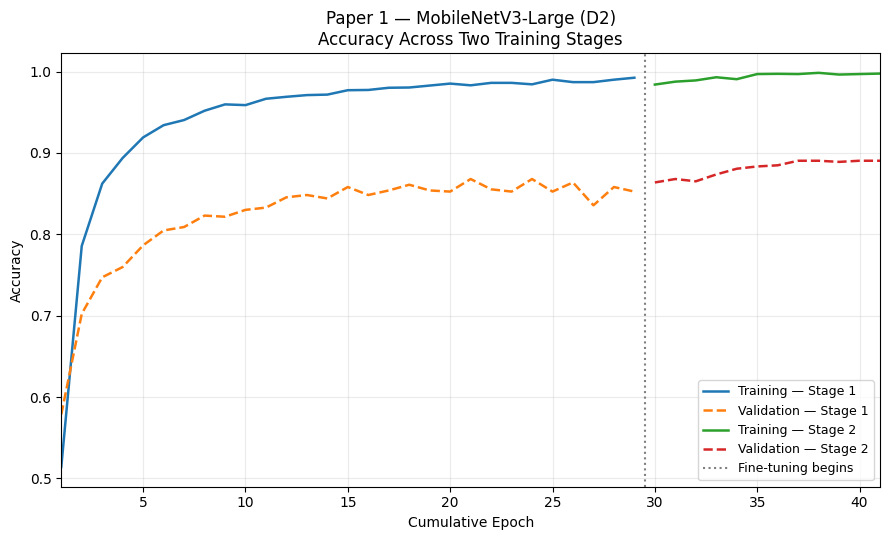

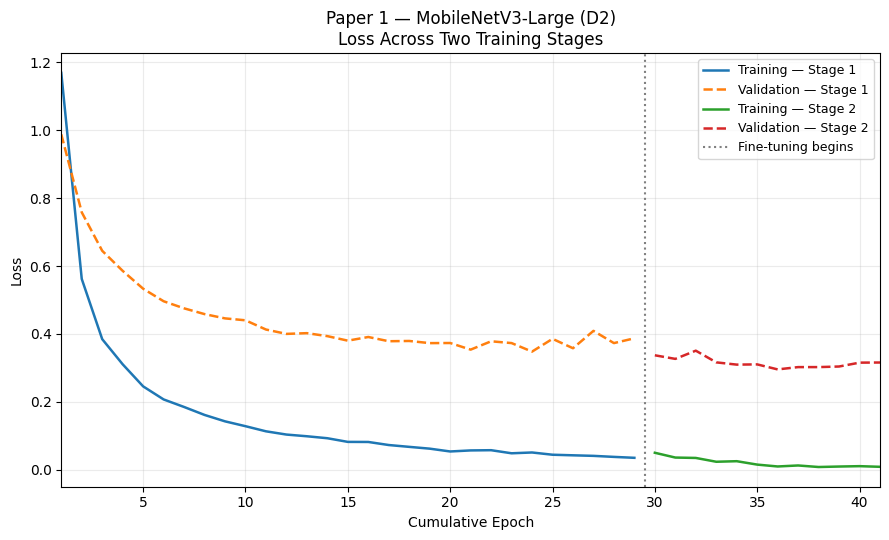


D2 TRAINING CURVE VERIFICATION
Stage 1 epochs: 29
Stage 2 epochs: 12
Total epochs: 41
Stage 1 best validation accuracy: 86.7977%
Stage 2 best validation accuracy: 89.0449%
Stage 1 best epoch: 21
Stage 2 best epoch: 8

SAVED FIGURES
Accuracy: /kaggle/working/Assignment02_Experiment3_D2/figures/paper1_d2_training_accuracy.png
Loss: /kaggle/working/Assignment02_Experiment3_D2/figures/paper1_d2_training_loss.png

INTEGRITY
Training histories: VERIFIED
Selected checkpoint: UNCHANGED
Additional training: NO
Additional test inference: NO

PAPER 1 D2 TRAINING FIGURES: PASSED


In [18]:

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================
# 1. VERIFY EXPERIMENT EVIDENCE
# =====================================

expected_d2_hash = (
    "261b97b6fa700197f2dde6bc0f833bf"
    "802bd1301c0611606400e990cfad2a185"
)

expected_checkpoint_hash = (
    "d21534ed22d938c4546008fef27277ccc"
    "eee578c3e02da82673f4deb6d1cda7a"
)

assert hashlib.sha256(
    d2_manifest_path.read_bytes()
).hexdigest() == expected_d2_hash

assert hashlib.sha256(
    STAGE2_BEST_PATH.read_bytes()
).hexdigest() == expected_checkpoint_hash

audit_path = (
    RUN_DIR /
    "final_test_evaluation/test_evidence_audit.json"
)

assert audit_path.is_file()

with audit_path.open() as f:
    audit = json.load(f)

assert audit["status"] == "PASS"
assert audit["test_samples"] == 713
assert audit["correct_predictions"] == 664

# =====================================
# 2. LOAD ORIGINAL TRAINING HISTORIES
# =====================================

stage1 = pd.read_csv(
    RUN_DIR / "stage1_history.csv"
)

stage2 = pd.read_csv(
    RUN_DIR / "stage2_history.csv"
)

required_columns = [
    "accuracy",
    "val_accuracy",
    "loss",
    "val_loss"
]

for history in [stage1, stage2]:
    assert all(
        column in history.columns
        for column in required_columns
    )

    assert np.isfinite(
        history[required_columns].to_numpy()
    ).all()

assert len(stage1) == 29
assert len(stage2) == 12

assert int(
    stage1["val_accuracy"].idxmax()
) + 1 == 21

assert int(
    stage2["val_accuracy"].idxmax()
) + 1 == 8

assert np.isclose(
    stage1["val_accuracy"].max(),
    618 / 712,
    atol=1e-7
)

assert np.isclose(
    stage2["val_accuracy"].max(),
    634 / 712,
    atol=1e-7
)

# =====================================
# 3. DEFINE CUMULATIVE EPOCH AXIS
# =====================================

stage1_epochs = np.arange(1, 30)
stage2_epochs = np.arange(30, 42)

assert len(stage1_epochs) == len(stage1)
assert len(stage2_epochs) == len(stage2)

figures_dir = RUN_DIR / "figures"

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

# =====================================
# 4. GENERATE AND SAVE FIGURES
# =====================================

def create_training_figure(
    metric,
    ylabel,
    filename
):
    output_path = figures_dir / filename

    assert not output_path.exists(), (
        f"Figure already exists: {output_path}"
    )

    fig, ax = plt.subplots(
        figsize=(9, 5.5)
    )

    # Stage 1: Frozen backbone
    ax.plot(
        stage1_epochs,
        stage1[metric],
        label="Training — Stage 1",
        linewidth=1.8
    )

    ax.plot(
        stage1_epochs,
        stage1["val_" + metric],
        linestyle="--",
        label="Validation — Stage 1",
        linewidth=1.8
    )

    # Stage 2: Partial fine-tuning
    ax.plot(
        stage2_epochs,
        stage2[metric],
        label="Training — Stage 2",
        linewidth=1.8
    )

    ax.plot(
        stage2_epochs,
        stage2["val_" + metric],
        linestyle="--",
        label="Validation — Stage 2",
        linewidth=1.8
    )

    # Stage boundary after epoch 29
    ax.axvline(
        29.5,
        color="gray",
        linestyle=":",
        linewidth=1.5,
        label="Fine-tuning begins"
    )

    ax.set_title(
        "Paper 1 — MobileNetV3-Large (D2)\n"
        + ylabel + " Across Two Training Stages"
    )

    ax.set_xlabel("Cumulative Epoch")
    ax.set_ylabel(ylabel)

    ax.set_xlim(1, 41)
    ax.grid(alpha=0.25)

    ax.legend(fontsize=9)

    fig.tight_layout()

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    assert output_path.is_file()
    assert output_path.stat().st_size > 0

    return output_path


accuracy_path = create_training_figure(
    metric="accuracy",
    ylabel="Accuracy",
    filename="paper1_d2_training_accuracy.png"
)

loss_path = create_training_figure(
    metric="loss",
    ylabel="Loss",
    filename="paper1_d2_training_loss.png"
)

# =====================================
# 5. REPORT VERIFICATION
# =====================================

print("\nD2 TRAINING CURVE VERIFICATION")

print("Stage 1 epochs:", len(stage1))
print("Stage 2 epochs:", len(stage2))
print(
    "Total epochs:",
    len(stage1) + len(stage2)
)

print(
    "Stage 1 best validation accuracy:",
    f"{stage1['val_accuracy'].max() * 100:.4f}%"
)

print(
    "Stage 2 best validation accuracy:",
    f"{stage2['val_accuracy'].max() * 100:.4f}%"
)

print(
    "Stage 1 best epoch:",
    stage1["val_accuracy"].idxmax() + 1
)

print(
    "Stage 2 best epoch:",
    stage2["val_accuracy"].idxmax() + 1
)

print("\nSAVED FIGURES")
print("Accuracy:", accuracy_path)
print("Loss:", loss_path)

print("\nINTEGRITY")
print("Training histories: VERIFIED")
print("Selected checkpoint: UNCHANGED")
print("Additional training: NO")
print("Additional test inference: NO")

print("\nPAPER 1 D2 TRAINING FIGURES: PASSED")
